# EDA

## Biblioteki

In [1]:
import os
import json
import pandas as pd
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, kruskal

## Ogólne spojrzenie na zebrane dane

In [2]:
base_path = "../data/training_set"
recordings_base = r"D:\MGR\Master\recordings"
metadata_base_dir = "../data/metadata"

In [3]:
# Lista folderów (kategorii)
categories = [
    d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))
]

# Zliczamy liczbę plików w każdym folderze
data = []
for category in categories:
    folder_path = os.path.join(base_path, category)
    file_count = len(
        [
            f
            for f in os.listdir(folder_path)
            if os.path.isfile(os.path.join(folder_path, f))
        ]
    )
    data.append({"category": category, "file_count": file_count})

df = pd.DataFrame(data)
df

,category,file_count
0,city_daylight,6044
1,city_daylight_rain,958
2,city_night,924
3,city_night_rain,378
4,highway_daylight,1393
5,highway_daylight_rain,336
6,highway_night,238
7,highway_night_rain,42
8,mountain_roads_daylight,819
9,mountain_roads_daylight_rain,151


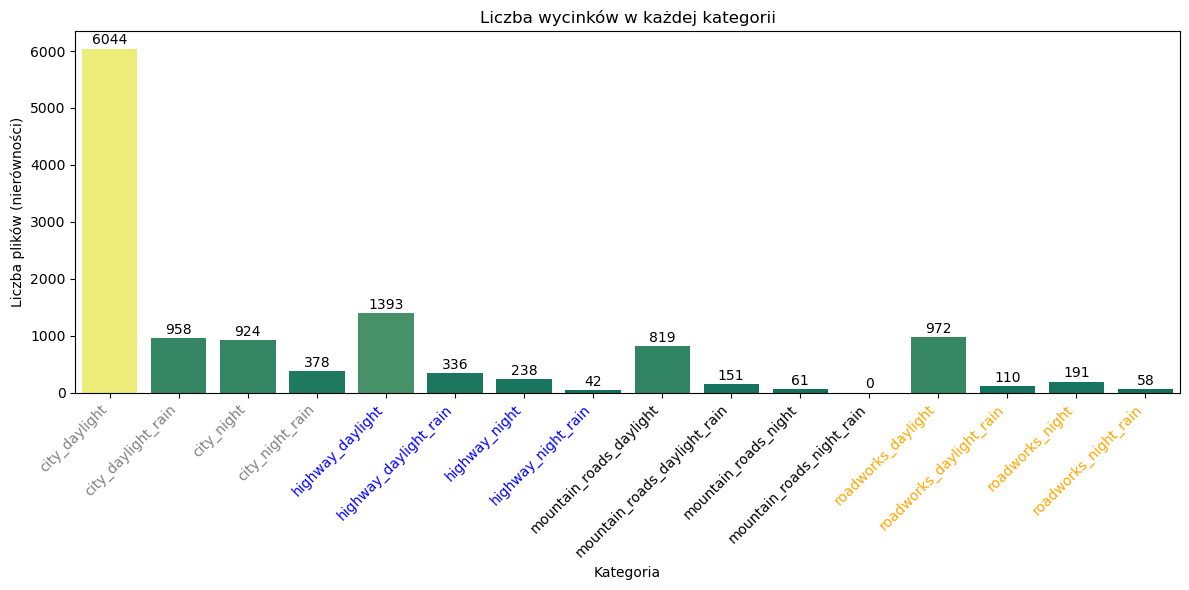

In [ ]:
prefix_colors = {
    "city": "grey",
    "highway": "blue",
    "mountain_roads": "green",
    "roadworks": "orange",
}

df["prefix"] = df["category"].apply(lambda x: x.split("_")[0])

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=df,
    x="category",
    y="file_count",
    hue="file_count",
    palette="summer",
    legend=False,
)
ax.set(
    title="Liczba wycinków w każdej kategorii",
    xlabel="Kategoria",
    ylabel="Liczba plików (nierówności)",
)

xtick_labels = ax.get_xticklabels()
for label in xtick_labels:
    category = label.get_text()
    prefix = category.split("_")[0]
    label.set_color(prefix_colors.get(prefix, "black"))

plt.xticks(rotation=45, ha="right")

for container in ax.containers:
    ax.bar_label(container, label_type="edge", padding=1)

plt.tight_layout()
plt.show()

C:\Users\adamp\AppData\Local\Temp\ipykernel_14200\3185437612.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, rotation=45, ha="right")


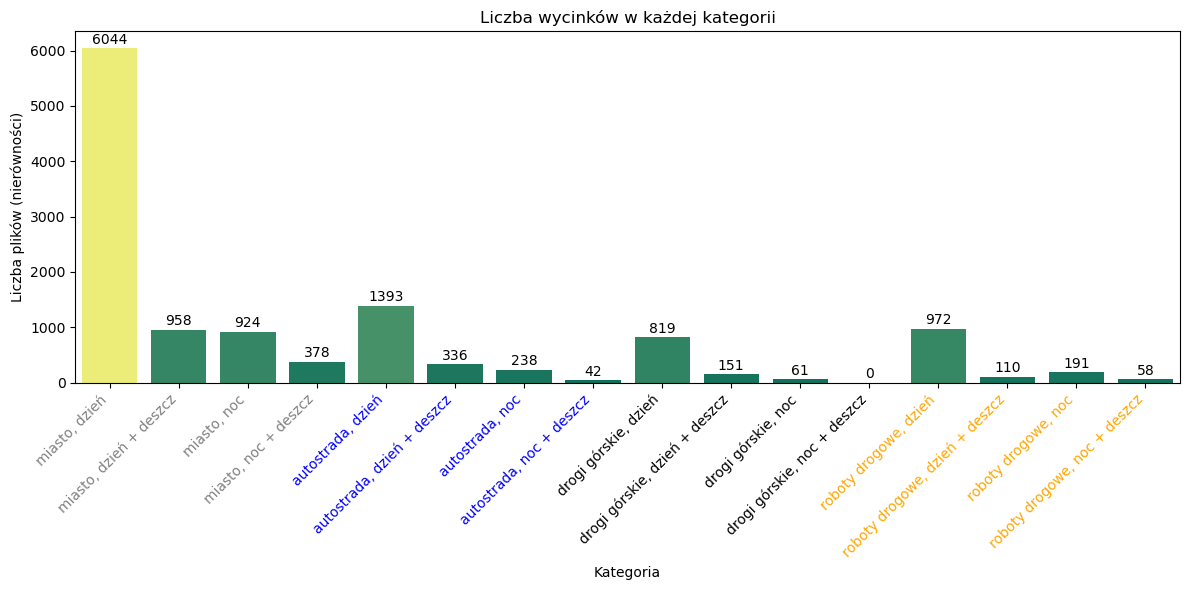

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1) mapowanie kategorii -> etykiety PL
pl_map = {
    "city_daylight": "miasto, dzień",
    "city_daylight_rain": "miasto, dzień + deszcz",
    "city_night": "miasto, noc",
    "city_night_rain": "miasto, noc + deszcz",
    "highway_daylight": "autostrada, dzień",
    "highway_daylight_rain": "autostrada, dzień + deszcz",
    "highway_night": "autostrada, noc",
    "highway_night_rain": "autostrada, noc + deszcz",
    "mountain_roads_daylight": "drogi górskie, dzień",
    "mountain_roads_daylight_rain": "drogi górskie, dzień + deszcz",
    "mountain_roads_night": "drogi górskie, noc",
    "mountain_roads_night_rain": "drogi górskie, noc + deszcz",
    "roadworks_daylight": "roboty drogowe, dzień",
    "roadworks_daylight_rain": "roboty drogowe, dzień + deszcz",
    "roadworks_night": "roboty drogowe, noc",
    "roadworks_night_rain": "roboty drogowe, noc + deszcz",
}

# 2) kolory etykiet po prefiksie
prefix_colors = {
    "city": "grey",
    "highway": "blue",
    "mountain_roads": "green",
    "roadworks": "orange",
}

df["prefix"] = df["category"].apply(lambda x: x.split("_")[0])

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=df,
    x="category",
    y="file_count",
    hue="file_count",
    palette="summer",
    legend=False,
)

ax.set(
    title="Liczba wycinków w każdej kategorii",
    xlabel="Kategoria",
    ylabel="Liczba plików (nierówności)",
)

# 3) podmień etykiety na polskie i pokoloruj wg prefiksu
labels = ax.get_xticklabels()
for lab in labels:
    cat = lab.get_text()
    pref = cat.split("_")[0]
    lab.set_text(pl_map.get(cat, cat))
    lab.set_color(prefix_colors.get(pref, "black"))

ax.set_xticklabels(labels, rotation=45, ha="right")

# 4) wartości nad słupkami
for container in ax.containers:
    ax.bar_label(container, label_type="edge", padding=1)

plt.tight_layout()

# 5) zapisz do pliku
out_path = "../data/figures/liczba_wycinkow_kategorie.png"
plt.savefig(out_path, dpi=200, bbox_inches="tight")

plt.show()

In [12]:
df["file_count"].sum()

np.int64(12675)

## Średnia liczba dziur na godzinę w każdej kategorii

In [6]:
avg_potholes_per_hour = df["file_count"].sum() * 60 / 2988
avg_potholes_per_hour

np.float64(254.51807228915663)

In [8]:
categories = [
    "city_daylight",
    "city_daylight_rain",
    "city_night",
    "city_night_rain",
    "highway_daylight",
    "highway_daylight_rain",
    "highway_night",
    "highway_night_rain",
    "mountain_roads_daylight",
    "mountain_roads_daylight_rain",
    "mountain_roads_night",
    "mountain_roads_night_rain",
    "roadworks_daylight",
    "roadworks_daylight_rain",
    "roadworks_night",
    "roadworks_night_rain",
]

data = []

for category in categories:
    # Liczba plików .jpg (wycinków) w training_set
    jpg_dir = os.path.join(base_path, category)
    jpg_count = len([f for f in os.listdir(jpg_dir) if f.endswith(".jpg")])

    # Liczba nagrań .mp4 (każde to 1 minuta)
    mp4_dir = os.path.join(recordings_base, category, "mp4")
    mp4_count = len([f for f in os.listdir(mp4_dir) if f.endswith(".mp4")])

    # Obliczenie średniej liczby dziur na godzinę
    total_minutes = mp4_count  # każde nagranie to 1 minuta
    hours = total_minutes / 60
    potholes_per_hour = jpg_count / hours if hours > 0 else 0

    data.append(
        {
            "category": category,
            "jpg_count": jpg_count,
            "video_count": mp4_count,
            "potholes_per_hour": potholes_per_hour,
        }
    )

df = pd.DataFrame(data)
df = df.sort_values("potholes_per_hour", ascending=False)

df.style.format({"potholes_per_hour": "{:.2f}"})

,category,jpg_count,video_count,potholes_per_hour
9,mountain_roads_daylight_rain,151,8,1132.50
8,mountain_roads_daylight,819,48,1023.75
1,city_daylight_rain,958,97,592.58
0,city_daylight,6044,885,409.76
12,roadworks_daylight,972,166,351.33
2,city_night,924,181,306.30
3,city_night_rain,378,80,283.50
10,mountain_roads_night,61,14,261.43
13,roadworks_daylight_rain,110,30,220.00
15,roadworks_night_rain,58,16,217.50


In [9]:
df["road_type"] = df["category"].apply(lambda x: x.split("_")[0])
df["road_type"] = df["road_type"].replace("mountain", "mountain_roads")

# Zgrupowanie i policzenie średniej liczby dziur na godzinę
grouped_avg = df.groupby("road_type")["potholes_per_hour"].mean().reset_index()

# Tylko interesujące prefixy
target_prefixes = ["mountain_roads", "city", "roadworks", "highway"]
grouped_avg = grouped_avg[grouped_avg["road_type"].isin(target_prefixes)]

# Zaokrąglenie i sort
grouped_avg["potholes_per_hour"] = grouped_avg["potholes_per_hour"].round(2)
grouped_avg = grouped_avg.sort_values("potholes_per_hour", ascending=False)

grouped_avg

,road_type,potholes_per_hour
2,mountain_roads,604.42
0,city,398.03
3,roadworks,250.26
1,highway,92.51


In [10]:
# Funkcja do ekstrakcji warunków pogodowych z nazwy kategorii
def extract_weather(category_name):
    if "daylight_rain" in category_name:
        return "daylight_rain"
    elif "night_rain" in category_name:
        return "night_rain"
    elif "daylight" in category_name:
        return "daylight"
    elif "night" in category_name:
        return "night"
    return "unknown"


# Dodanie kolumny weather
df["weather"] = df["category"].apply(extract_weather)

# Grupowanie po warunkach pogodowych
weather_avg = df.groupby("weather")["potholes_per_hour"].mean().reset_index()

weather_avg = weather_avg.sort_values("potholes_per_hour", ascending=False)

weather_avg

,weather,potholes_per_hour
1,daylight_rain,523.328153
0,daylight,467.952479
2,night,207.691910
3,night_rain,146.250000


### Korelacja między średnią liczbą znalezionych dziur w ciągu godziny a pogodą oraz rodzajem drogi

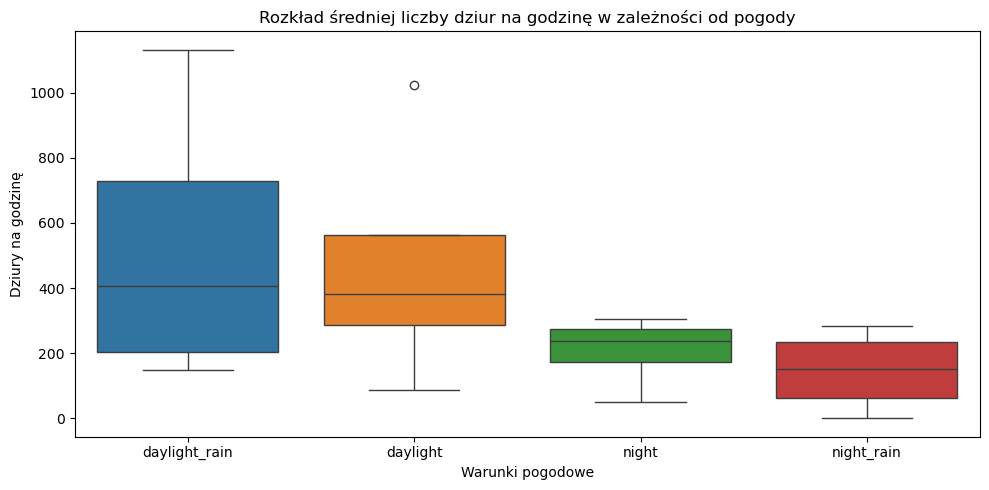

In [17]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="weather", y="potholes_per_hour", hue="weather", legend=False)
plt.title("Rozkład średniej liczby dziur na godzinę w zależności od pogody")
plt.xlabel("Warunki pogodowe")
plt.ylabel("Dziury na godzinę")
plt.tight_layout()
plt.show()

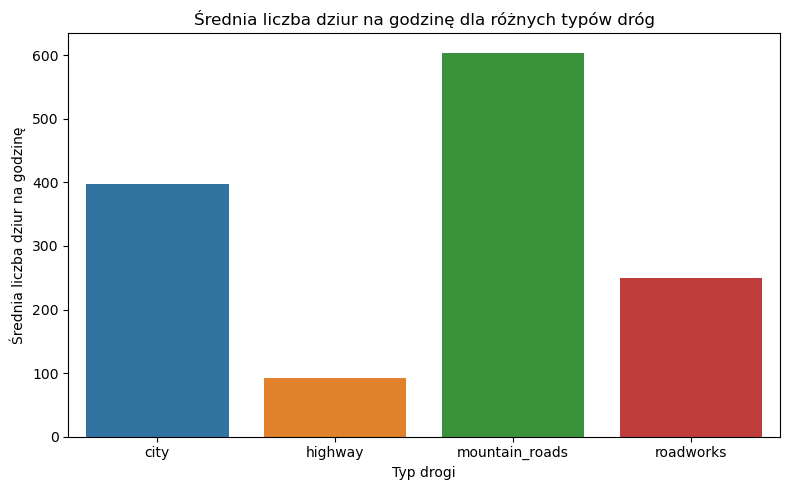

In [18]:
prefix_avg = df.groupby("road_type")["potholes_per_hour"].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    data=prefix_avg, x="road_type", y="potholes_per_hour", hue="road_type", legend=False
)
plt.title("Średnia liczba dziur na godzinę dla różnych typów dróg")
plt.xlabel("Typ drogi")
plt.ylabel("Średnia liczba dziur na godzinę")
plt.tight_layout()
plt.show()

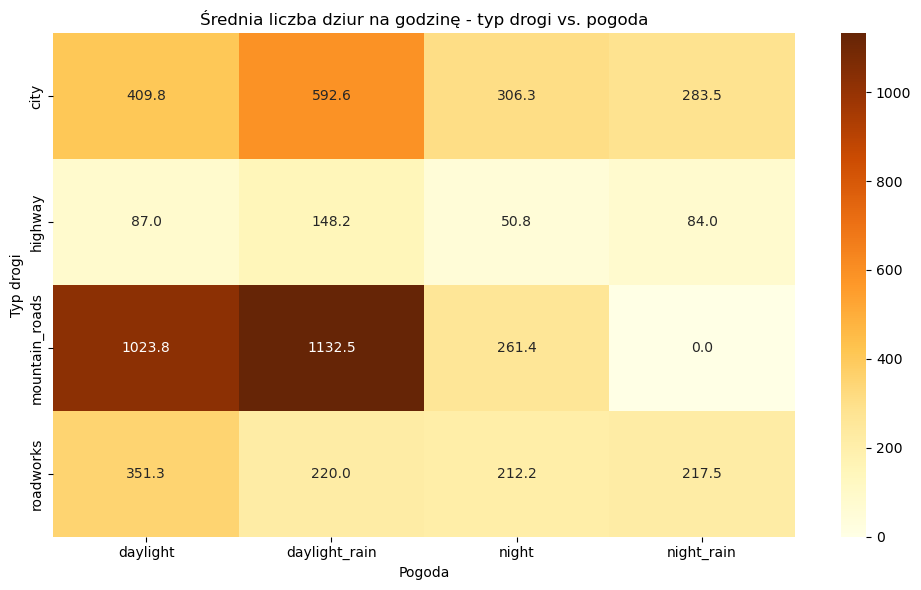

In [12]:
pivot_df = df.pivot_table(
    index="road_type", columns="weather", values="potholes_per_hour", aggfunc="mean"
)

plt.figure(figsize=(10, 6))
sns.heatmap(pivot_df, annot=True, fmt=".1f", cmap="YlOrBr")
plt.title("Średnia liczba dziur na godzinę - typ drogi vs. pogoda")
plt.xlabel("Pogoda")
plt.ylabel("Typ drogi")
plt.tight_layout()
plt.show()

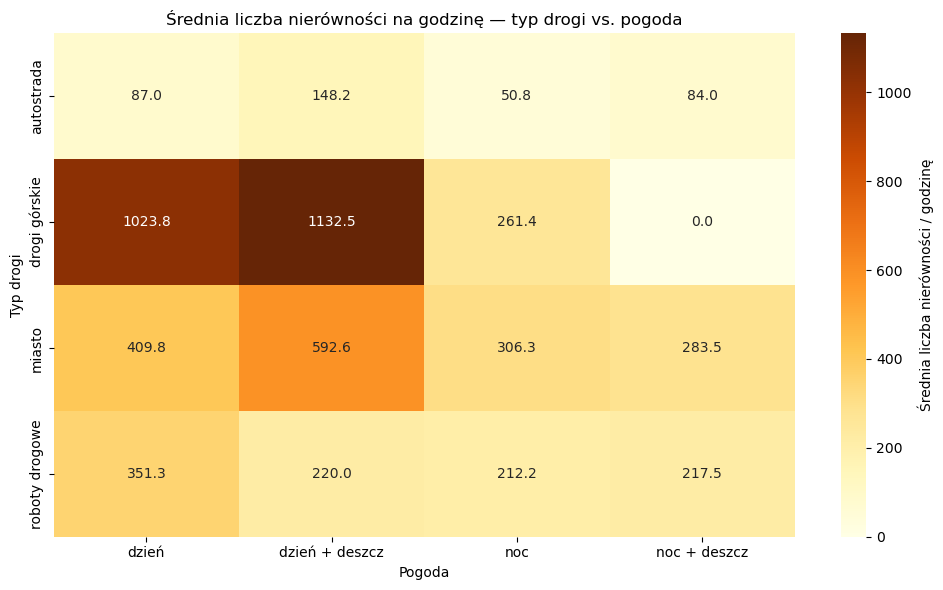

In [ ]:
# mapowania nazw → PL
road_map = {
    "city": "miasto",
    "highway": "autostrada",
    "mountain_roads": "drogi górskie",
    "roadworks": "roboty drogowe",
}
weather_map = {
    "daylight": "dzień",
    "daylight_rain": "dzień + deszcz",
    "night": "noc",
    "night_rain": "noc + deszcz",
}

# pivot z polskimi etykietami
pivot_pl = df.assign(
    road_type=df["road_type"].map(road_map),
    weather=df["weather"].map(weather_map),
).pivot_table(
    index="road_type", columns="weather", values="potholes_per_hour", aggfunc="mean"
)

plt.figure(figsize=(10, 6))
ax = sns.heatmap(
    pivot_pl,
    annot=True,
    fmt=".1f",
    cmap="YlOrBr",
    cbar_kws={"label": "Średnia liczba nierówności / godzinę"},
)
ax.set_title("Średnia liczba nierówności na godzinę — typ drogi vs. pogoda")
ax.set_xlabel("Pogoda")
ax.set_ylabel("Typ drogi")
plt.tight_layout()
# zapisz do pliku (jeśli potrzebujesz)
plt.savefig(
    "../data/figures/heatmap_dziury_typ_vs_pogoda.png", dpi=200, bbox_inches="tight"
)
plt.show()

#### Pearson vs Spearman
Cecha	                        Pearson	                        Spearman
Typ korelacji	                liniowa	                        monotoniczna (rosnąca/malejąca, niekoniecznie liniowo)
Zakłada rozkład normalny?	    Tak (dla sensownych wniosków)	Nie
Wrażliwa na wartości odstające?	Tak	                            Mniej
Nadaje się do danych liczbowych	Tak	                            Tak
Nadaje się do rang/kategorii	Nie	                            Tak (rangi, porządek)

#### W badanym przypadku przypadku:
dziury_na_godzine to wartość liczbowa (ciągła)

prefix i weather są kategoryczne (nienumeryczne, nieliniowe)

Lepszy Spearmana – bo mierzy ogólną zależność monotoniczną i działa dobrze z rangami lub przekształconymi kategoriami.

In [20]:
# Zakoduj prefix i weather jako liczby
weather_order = {
    "daylight": 1,
    "daylight_rain": 2,
    "night": 3,
    "night_rain": 4,
}

df["weather_num"] = df["weather"].map(weather_order)

road_type_order = {
    "highway": 1,
    "roadworks": 2,
    "city": 3,
    "mountain_roads": 4,
}

df["weather_num"] = df["weather"].map(weather_order)
df["road_type_num"] = df["road_type"].map(road_type_order)
df

,category,jpg_count,video_count,potholes_per_hour,road_type,weather,weather_num,road_type_num
9,mountain_roads_daylight_rain,151,8,1132.500000,mountain_roads,daylight_rain,2,4
8,mountain_roads_daylight,819,48,1023.750000,mountain_roads,daylight,1,4
1,city_daylight_rain,958,97,592.577320,city,daylight_rain,2,3
0,city_daylight,6044,885,409.762712,city,daylight,1,3
12,roadworks_daylight,972,166,351.325301,roadworks,daylight,1,2
2,city_night,924,181,306.298343,city,night,3,3
3,city_night_rain,378,80,283.500000,city,night_rain,4,3
10,mountain_roads_night,61,14,261.428571,mountain_roads,night,3,4
13,roadworks_daylight_rain,110,30,220.000000,roadworks,daylight_rain,2,2
15,roadworks_night_rain,58,16,217.500000,roadworks,night_rain,4,2


In [21]:
# Korelacja Spearmana
corr_road_type, pval_road_type = spearmanr(df["road_type_num"], df["potholes_per_hour"])
corr_weather, pval_weather = spearmanr(df["weather_num"], df["potholes_per_hour"])

print(
    f"Korelacja Spearmana: typ drogi vs dziury/h = {corr_road_type:.2f}, p-value = {pval_road_type:.4f}"
)
print(
    f"Korelacja Spearmana: pogoda vs dziury/h = {corr_weather:.2f}, p-value = {pval_weather:.4f}"
)

Korelacja Spearmana: typ drogi vs dziury/h = 0.58, p-value = 0.0180
Korelacja Spearmana: pogoda vs dziury/h = -0.51, p-value = 0.0439


#### Interpretacja:
Korelacja blisko 1 lub -1 oznacza silną zależność (odpowiednio dodatnią lub ujemną)

p-value < 0.05 ⇒ statystycznie istotna korelacja

#### 1. Korelacja Spearmana: typ drogi vs dziury/h = +0.58, p = 0.0180
Co to oznacza?
Dodatnia korelacja (0.58): im „wyższy” kod przypisany typowi drogi, tym więcej dziur na godzinę.

p-value < 0.05 → wynik jest statystycznie istotny (czyli nieprzypadkowy).

Wynik sugeruje, że:
- Na bardziej „problematycznych” typach dróg (np. górskich, miejskich) wykrywa się więcej dziur.
- Jest to zgodne z intuicją – np. górskie i miejskie drogi to miejsca, gdzie realnie może być więcej uszkodzeń. Logicznie, także remonty powinny mieć więcej uszkodzeń, jednakże w przypadku zebranych danych niemal 100% robót drogowych występowało na autostradach, w związku z czym liczba nierówności była tam ograniczona, a nagrania charakteryzowały się jedynie większą liczbą pachołków/słupków ostrzegawczych oraz wolniejszym ruchem.

#### 2. Korelacja Spearmana: pogoda vs dziury/h = –0.51, p = 0.0439
Co to oznacza?
Ujemna korelacja (–0.51): im gorsze warunki pogodowe, tym mniej dziur na godzinę.

p-value < 0.05 → również statystycznie istotne.

Wynik sugeruje, że:
- W trudniejszych warunkach (noc, deszcz) wykrywa się mniej dziur.

Może to oznaczać:
- słabszą widoczność, co utrudnia oznaczanie dziur,
- problemy techniczne (kamera nie widzi dobrze),
- lub realnie mniej dziur, np. bo nagrywa się inne trasy nocą.

## Analiza wielkości dziur

Średnia wielkość dla każdego nagrania!

In [17]:
data_list = []

for category in os.listdir(metadata_base_dir):
    category_path = os.path.join(metadata_base_dir, category)
    if os.path.isdir(category_path):
        weather = extract_weather(category)  # wyciągamy pogodę z kategorii
        road_type = category.split("_")[0]
        if road_type == "mountain":
            road_type = "mountain_roads"

        for file in os.listdir(category_path):
            file_path = os.path.join(category_path, file)
            with open(file_path, "r", encoding="utf-8") as f:
                json_data = json.load(f)

                for key, entry in json_data["metadata"].items():
                    x, y, w, h = entry["xy"][1:]
                    x1, y1 = x, y
                    x2, y2 = x + w, y + h
                    w_val = x2 - x1
                    h_val = y2 - y1

                    data_list.append(
                        {
                            "category": category,
                            "road_type": road_type,
                            "weather": weather,
                            "w": w_val,
                            "h": h_val,
                        }
                    )

df_meta = pd.DataFrame(data_list)
print(df_meta.head())

        category road_type   weather         w        h
0  city_daylight      city  daylight   192.676  101.409
1  city_daylight      city  daylight   152.113   68.450
2  city_daylight      city  daylight   950.704   68.450
3  city_daylight      city  daylight  1285.352   86.197
4  city_daylight      city  daylight   121.690   60.845


In [18]:
mean_sizes = df_meta.groupby("road_type")[["w", "h"]].mean().reset_index()

mean_sizes

,road_type,w,h
0,city,161.278931,58.714255
1,highway,366.634911,64.091297
2,mountain_roads,166.031775,108.272173
3,roadworks,192.380821,79.025807


In [19]:
road_type_order = {
    "highway": 1,
    "roadworks": 2,
    "city": 3,
    "mountain_roads": 4,
}

df_meta["road_type_num"] = df_meta["road_type"].map(road_type_order)

In [20]:
# Spearman dla szerokości
corr_w, pval_w = spearmanr(df_meta["road_type_num"], df_meta["w"])
print(
    f"Korelacja Spearmana (road_type vs szerokość w): {corr_w:.3f}, p-value = {pval_w:.4f}"
)

# Spearman dla wysokości
corr_h, pval_h = spearmanr(df_meta["road_type_num"], df_meta["h"])
print(
    f"Korelacja Spearmana (road_type vs wysokość h): {corr_h:.3f}, p-value = {pval_h:.4f}"
)

Korelacja Spearmana (road_type vs szerokość w): -0.261, p-value = 0.0000
Korelacja Spearmana (road_type vs wysokość h): 0.002, p-value = 0.8153


1. Korelacja dla szerokości (w):
- Wartość korelacji wynosi -0.261, co oznacza słabą do umiarkowanej ujemną zależność monotoniczną między numerem typu drogi a szerokością dziur.
- Ponieważ wyższe wartości road_type_num to bardziej „górskie” i miejskie drogi (od autostrad do górskich), ujemny znak oznacza, że w miarę przechodzenia od autostrady (1) do dróg górskich (4) szerokość dziur ma tendencję do zmniejszania się. Jest to spójne z własnymi obserwacjami, w czasie których zauważono, że na autostradach przeważają poprzeczne podłużne nierówności (np. dylatacje), a bardziej typowe wyrwy kształtem przypominające koła (w przypadku przygotowanych wycinków - kwadraty) zdarzają się bardzo rzadko.
- P-value = 0.0000 wskazuje, że ta korelacja jest statystycznie istotna, czyli jest mało prawdopodobne, że wynik jest efektem przypadku.

2. Korelacja dla wysokości (h):
- Wartość korelacji to 0.002, bardzo bliska zeru, co oznacza brak monotonicznej zależności między typem drogi a wysokością dziur.
- P-value = 0.8153 jest duże, więc nie można uznać tej zależności za istotną statystycznie.

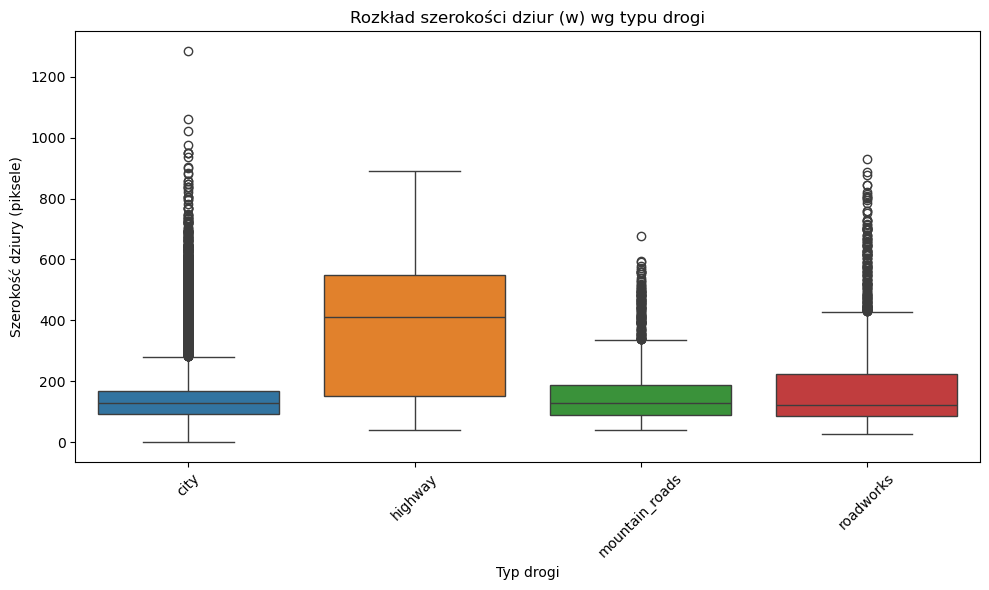

In [50]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_meta, x="road_type", y="w", hue="road_type", legend=False)
plt.title("Rozkład szerokości dziur (w) wg typu drogi")
plt.xlabel("Typ drogi")
plt.ylabel("Szerokość dziury (piksele)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

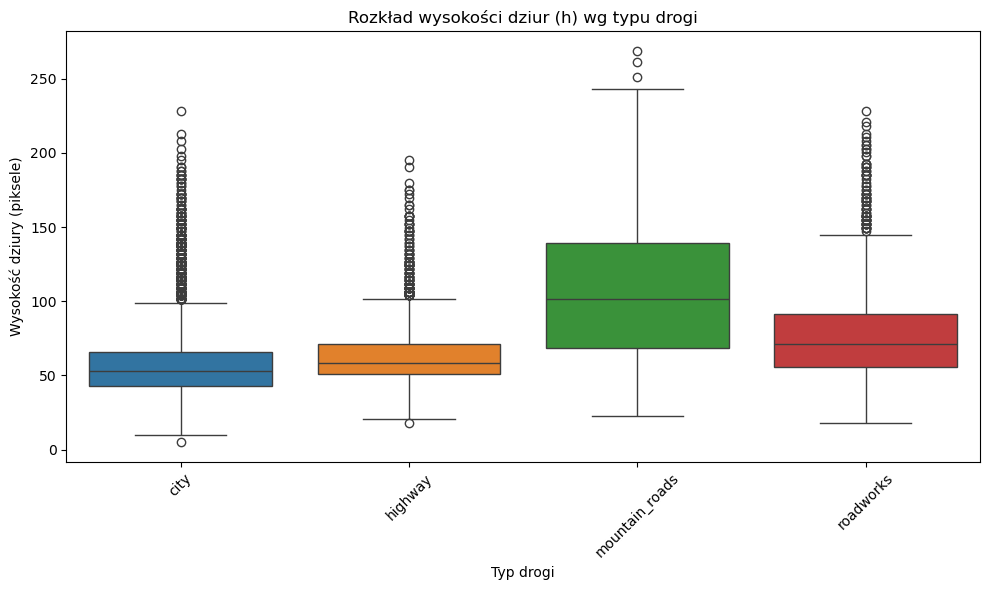

In [51]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_meta, x="road_type", y="h", hue="road_type", legend=False)
plt.title("Rozkład wysokości dziur (h) wg typu drogi")
plt.xlabel("Typ drogi")
plt.ylabel("Wysokość dziury (piksele)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

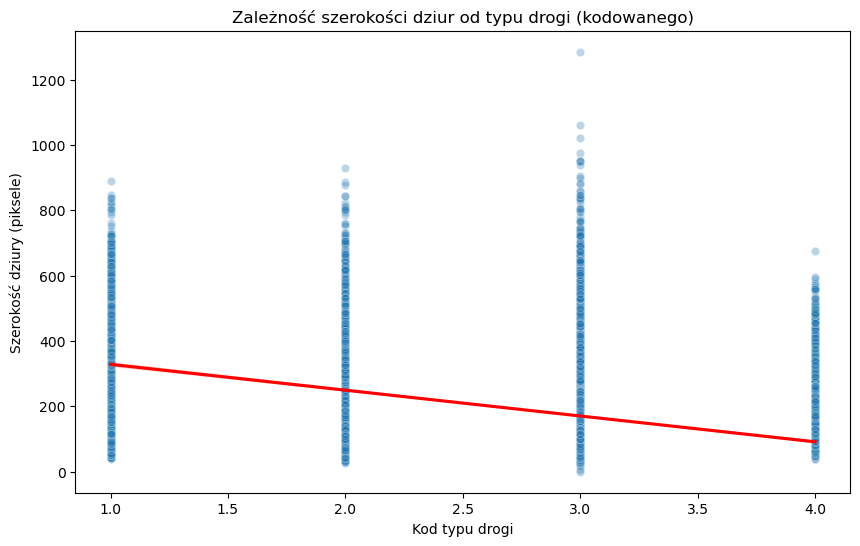

In [52]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_meta, x="road_type_num", y="w", alpha=0.3)
sns.regplot(data=df_meta, x="road_type_num", y="w", scatter=False, color="red")
plt.title("Zależność szerokości dziur od typu drogi (kodowanego)")
plt.xlabel("Kod typu drogi")
plt.ylabel("Szerokość dziury (piksele)")
plt.show()

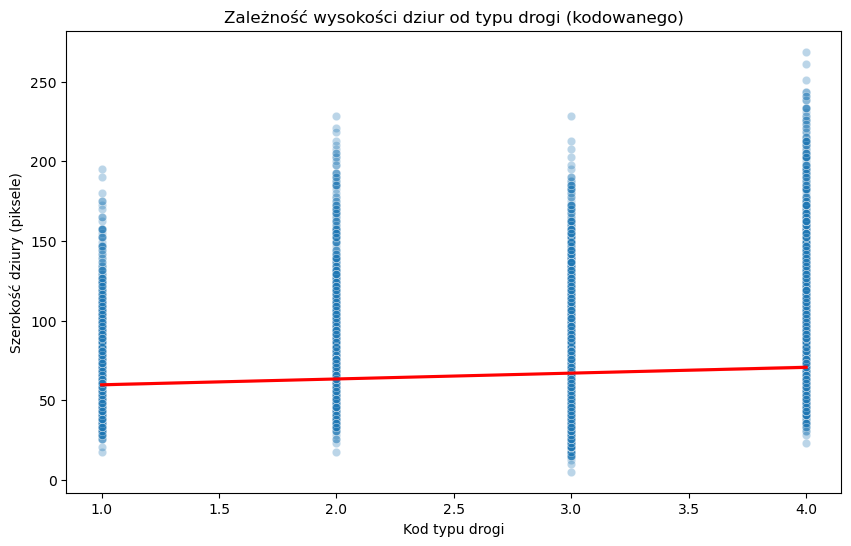

In [53]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_meta, x="road_type_num", y="h", alpha=0.3)
sns.regplot(data=df_meta, x="road_type_num", y="h", scatter=False, color="red")
plt.title("Zależność wysokości dziur od typu drogi (kodowanego)")
plt.xlabel("Kod typu drogi")
plt.ylabel("Szerokość dziury (piksele)")
plt.show()

## Analiza wielowymiarowa - wielkość dziur i częstość ich występowania

In [21]:
# df
# df.to_csv('../data/df.csv')


df_meta
# df_meta.to_csv('../data/df_meta.csv')

,category,road_type,weather,w,h,road_type_num
0,city_daylight,city,daylight,192.676,101.409,3
1,city_daylight,city,daylight,152.113,68.450,3
2,city_daylight,city,daylight,950.704,68.450,3
3,city_daylight,city,daylight,1285.352,86.197,3
4,city_daylight,city,daylight,121.690,60.845,3
...,...,...,...,...,...,...
12705,roadworks_night_rain,roadworks,night_rain,109.015,63.380,2
12706,roadworks_night_rain,roadworks,night_rain,45.633,32.958,2
12707,roadworks_night_rain,roadworks,night_rain,43.098,32.958,2
12708,roadworks_night_rain,roadworks,night_rain,65.915,81.127,2


In [22]:
# Agregacja df_meta - średnia szerokość i wysokość dziur dla każdej kombinacji road_type + weather
agg_meta = (
    df_meta.groupby(["road_type", "weather"])[["w", "h"]]
    .mean()
    .reset_index()
    .rename(columns={"w": "mean_width", "h": "mean_height"})
)

# Łączenie z df po road_type i weather
df_merged = df.merge(agg_meta, on=["road_type", "weather"], how="left")

df_merged

,category,jpg_count,video_count,potholes_per_hour,road_type,weather,mean_width,mean_height
0,mountain_roads_daylight_rain,151,8,1132.500000,mountain_roads,daylight_rain,181.192081,101.525920
1,mountain_roads_daylight,819,48,1023.750000,mountain_roads,daylight,156.904846,109.193396
2,city_daylight_rain,958,97,592.577320,city,daylight_rain,181.741287,65.727632
3,city_daylight,6044,885,409.762712,city,daylight,156.385508,57.565766
4,roadworks_daylight,972,166,351.325301,roadworks,daylight,184.587900,82.712547
5,city_night,924,181,306.298343,city,night,154.900320,57.083405
6,city_night_rain,378,80,283.500000,city,night_rain,203.668700,63.387028
7,mountain_roads_night,61,14,261.428571,mountain_roads,night,251.193669,112.588264
8,roadworks_daylight_rain,110,30,220.000000,roadworks,daylight_rain,185.992359,70.225325
9,roadworks_night_rain,58,16,217.500000,roadworks,night_rain,234.900372,66.046692


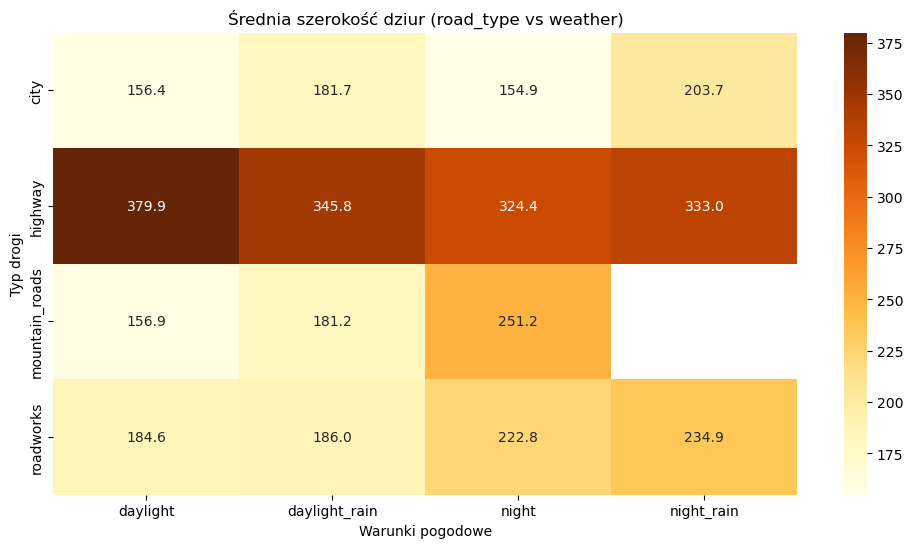

In [23]:
# Heatmapa średniej szerokości dziur
plt.figure(figsize=(12, 6))
heatmap_width = df_merged.pivot(
    index="road_type", columns="weather", values="mean_width"
)
sns.heatmap(heatmap_width, annot=True, fmt=".1f", cmap="YlOrBr")
plt.title("Średnia szerokość dziur (road_type vs weather)")
plt.ylabel("Typ drogi")
plt.xlabel("Warunki pogodowe")
plt.show()

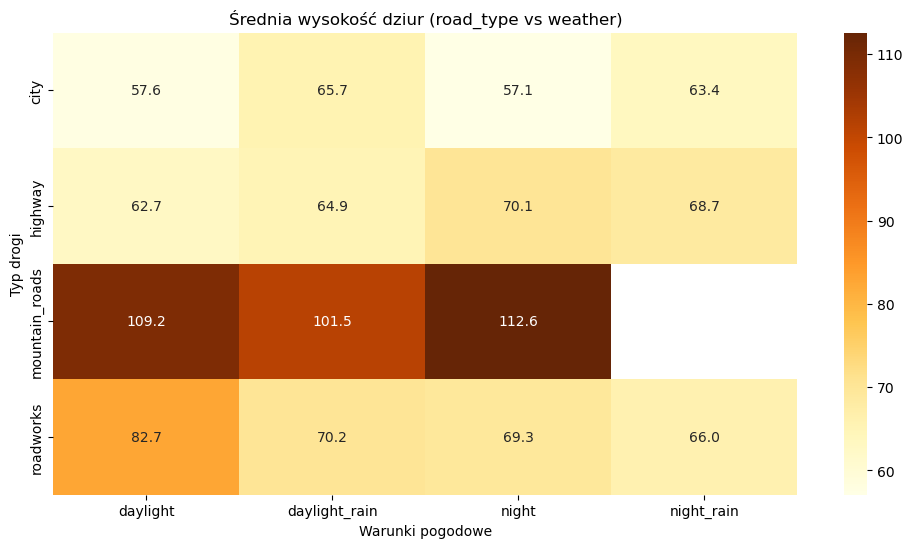

In [24]:
# Heatmapa średniej wysokości dziur
plt.figure(figsize=(12, 6))
heatmap_height = df_merged.pivot(
    index="road_type", columns="weather", values="mean_height"
)
sns.heatmap(heatmap_height, annot=True, fmt=".1f", cmap="YlOrBr")
plt.title("Średnia wysokość dziur (road_type vs weather)")
plt.ylabel("Typ drogi")
plt.xlabel("Warunki pogodowe")
plt.show()

In [ ]:
# Interaktywny wykres 3D (plotly)
fig = px.scatter_3d(
    df_merged,
    x="mean_width",
    y="mean_height",
    z="potholes_per_hour",
    color="road_type",
    symbol="weather",
    size="potholes_per_hour",
    hover_data=["road_type", "weather", "category"],
    title="Średnia liczba dziur na godzinę i rozmiary dziur (3D)",
)
fig.show()

## Analiza rozkładu rozmiarów dziur dla każdego typu drogi i warunków pogodowych

In [25]:
# Aspect_ratio (szerokość / wysokość)
df_meta["aspect_ratio"] = df_meta["w"] / df_meta["h"]
df_meta

,category,road_type,weather,w,h,road_type_num,aspect_ratio
0,city_daylight,city,daylight,192.676,101.409,3,1.899989
1,city_daylight,city,daylight,152.113,68.450,3,2.222250
2,city_daylight,city,daylight,950.704,68.450,3,13.889028
3,city_daylight,city,daylight,1285.352,86.197,3,14.911795
4,city_daylight,city,daylight,121.690,60.845,3,2.000000
...,...,...,...,...,...,...,...
12705,roadworks_night_rain,roadworks,night_rain,109.015,63.380,2,1.720022
12706,roadworks_night_rain,roadworks,night_rain,45.633,32.958,2,1.384580
12707,roadworks_night_rain,roadworks,night_rain,43.098,32.958,2,1.307664
12708,roadworks_night_rain,roadworks,night_rain,65.915,81.127,2,0.812492


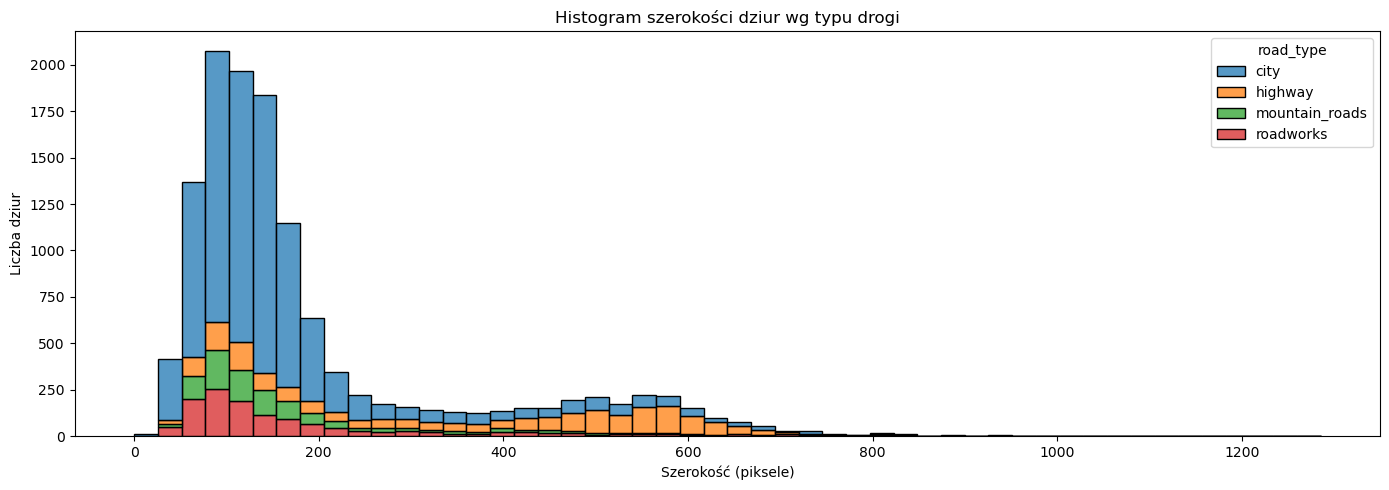

In [79]:
# Histogram szerokości
plt.figure(figsize=(14, 5))
sns.histplot(data=df_meta, x="w", hue="road_type", multiple="stack", bins=50)
plt.title("Histogram szerokości dziur wg typu drogi")
plt.xlabel("Szerokość (piksele)")
plt.ylabel("Liczba dziur")
plt.tight_layout()
plt.show()

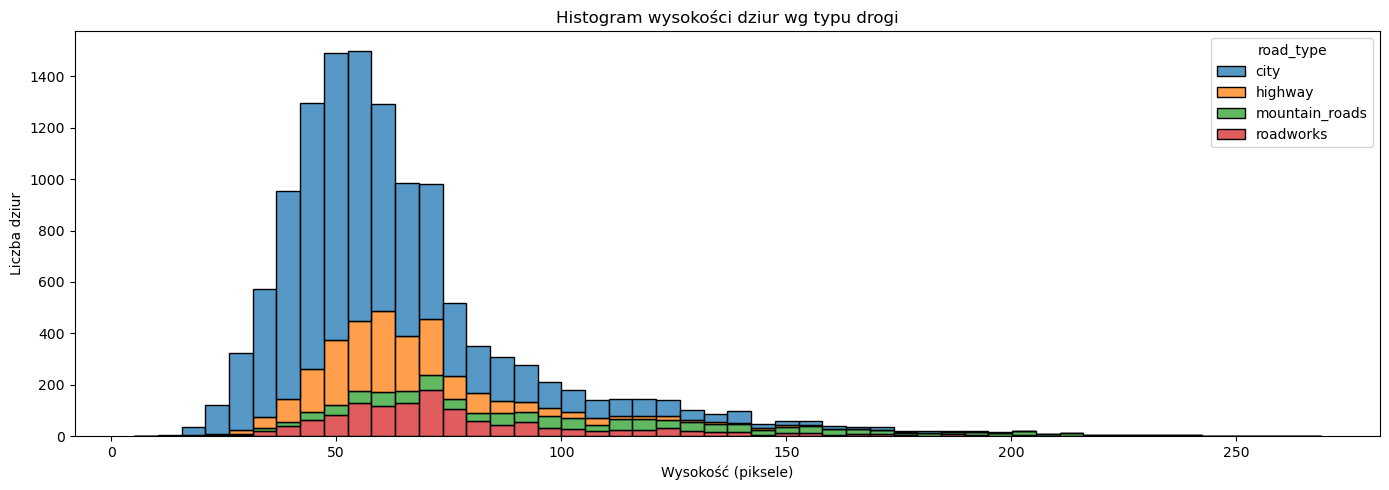

In [80]:
# Histogram wysokości
plt.figure(figsize=(14, 5))
sns.histplot(data=df_meta, x="h", hue="road_type", multiple="stack", bins=50)
plt.title("Histogram wysokości dziur wg typu drogi")
plt.xlabel("Wysokość (piksele)")
plt.ylabel("Liczba dziur")
plt.tight_layout()
plt.show()

- Drogi miejskie (city) mają najwięcej detekcji, ale szerokości dziur są z reguły mniejsze (większość <200 px).
- Autostrady (highway) mają wyraźnie większy udział szerokich dziur – pojawiają się detekcje powyżej 400–600 px.
- Drogi górskie (mountain_roads) i remonty (roadworks) mają umiarkowane rozkłady – średnie dziury są większe niż w miastach, ale mniejsze niż na autostradach.
- Wysokość dziur (h) jest mniej zróżnicowana niż szerokość – w większości przypadków 50–150 px.

Wniosek: szerokość dziur jest bardziej zależna od typu drogi niż ich wysokość – autostrady mają szersze anomalie, co może wynikać z charakteru ich uszkodzeń (pęknięcia wzdłużne, koleiny).

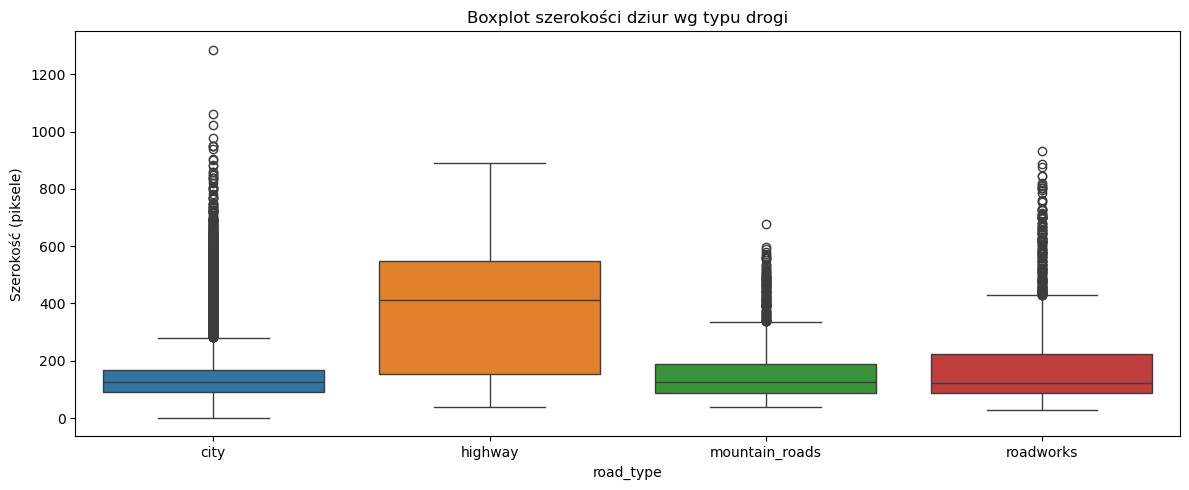

In [67]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_meta, x="road_type", y="w", hue="road_type", legend=False)
plt.title("Boxplot szerokości dziur wg typu drogi")
plt.ylabel("Szerokość (piksele)")
plt.tight_layout()
plt.show()

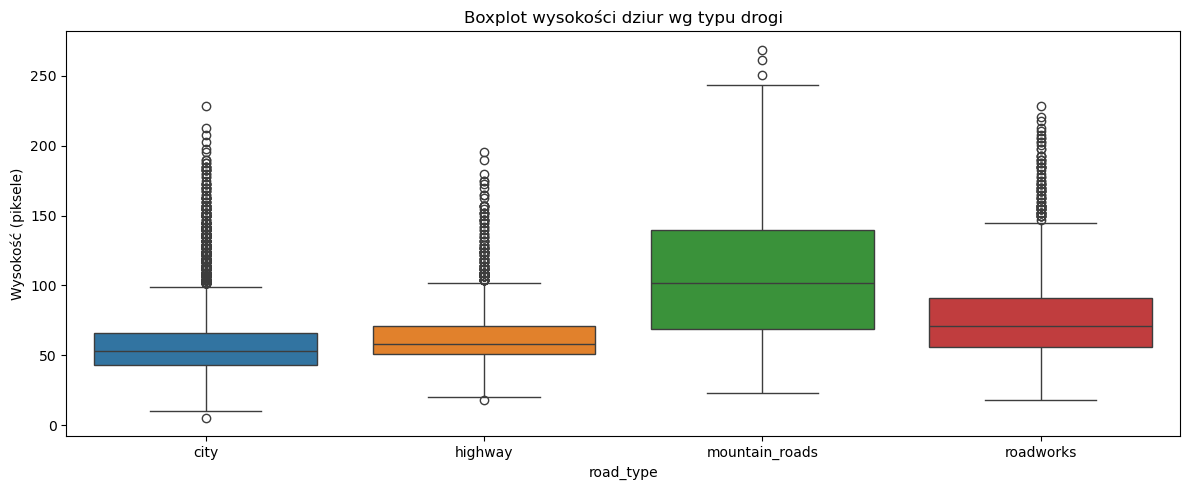

In [68]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_meta, x="road_type", y="h", hue="road_type", legend=False)
plt.title("Boxplot wysokości dziur wg typu drogi")
plt.ylabel("Wysokość (piksele)")
plt.tight_layout()
plt.show()

In [ ]:
map_pl = {
    "city": "miasto",
    "highway": "autostrada",
    "mountain_roads": "drogi górskie",
    "roadworks": "roboty drogowe",
}

# Nowa kolumna z polskimi etykietami
df_meta = df_meta.copy()
df_meta["Typ drogi"] = df_meta["road_type"].map(map_pl).fillna(df_meta["road_type"])

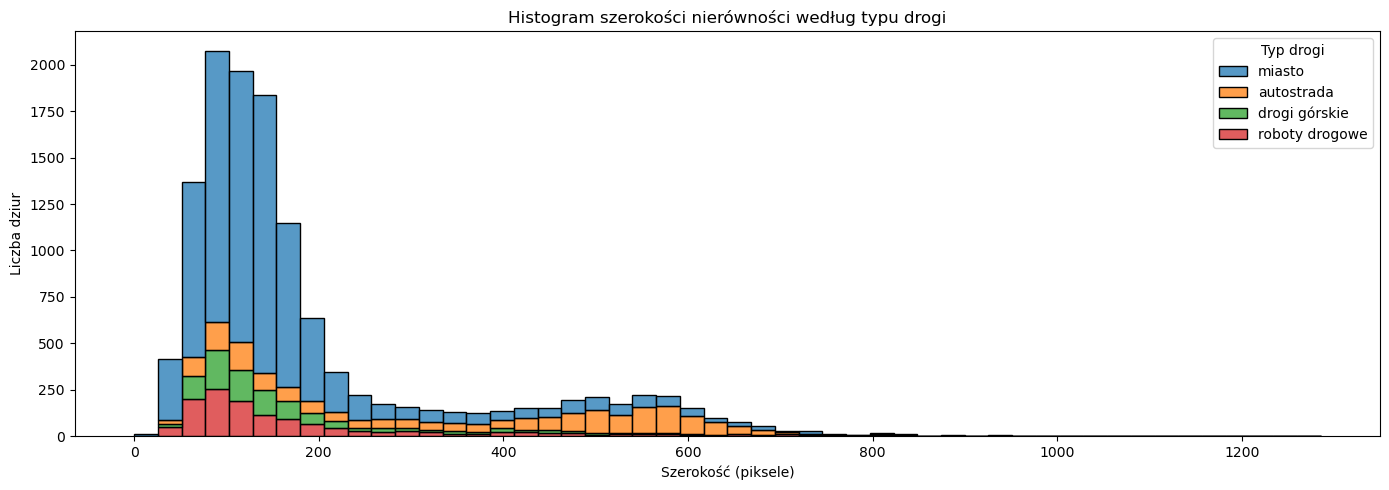

In [ ]:
plt.figure(figsize=(14, 5))
ax = sns.histplot(data=df_meta, x="w", hue="Typ drogi", multiple="stack", bins=50)
ax.set_title("Histogram szerokości nierówności według typu drogi")
ax.set_xlabel("Szerokość (piksele)")
ax.set_ylabel("Liczba dziur")
plt.tight_layout()
plt.savefig(
    "../data/figures/hist_szerokosc_typ_drogi.png", dpi=300, bbox_inches="tight"
)
plt.show()

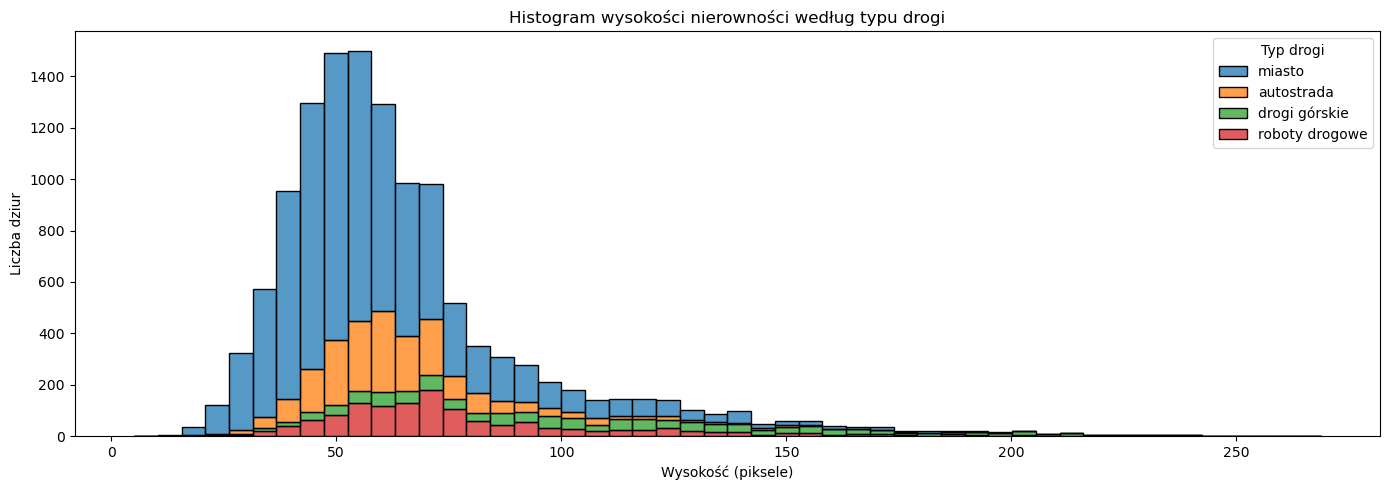

In [ ]:
plt.figure(figsize=(14, 5))
ax = sns.histplot(data=df_meta, x="h", hue="Typ drogi", multiple="stack", bins=50)
ax.set_title("Histogram wysokości nierowności według typu drogi")
ax.set_xlabel("Wysokość (piksele)")
ax.set_ylabel("Liczba dziur")
plt.tight_layout()
plt.savefig("../data/figures/hist_wysokosc_typ_drogi.png", dpi=300, bbox_inches="tight")
plt.show()

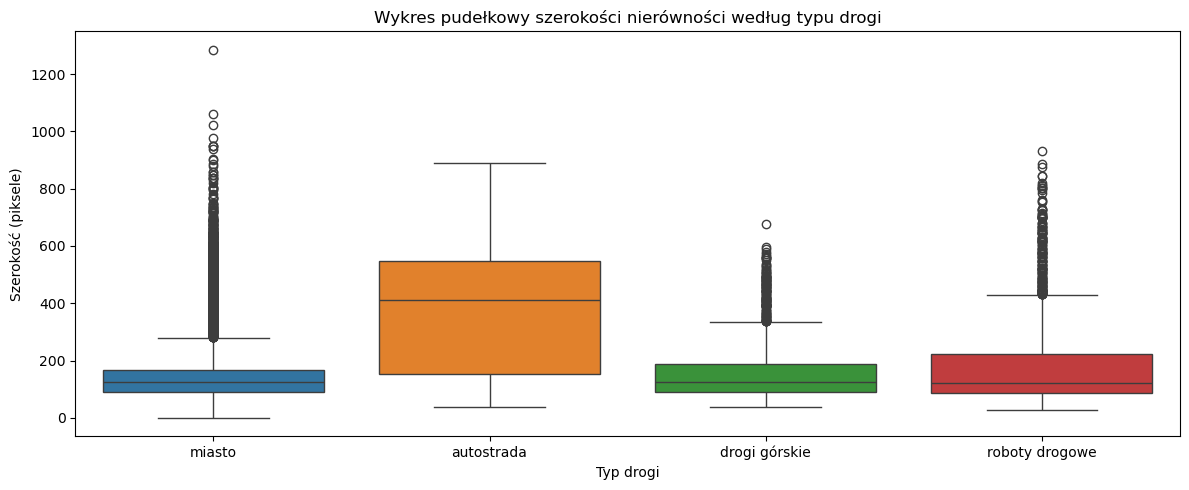

In [ ]:
plt.figure(figsize=(12, 5))
ax = sns.boxplot(data=df_meta, x="Typ drogi", y="w", hue="Typ drogi", showfliers=True)
ax.set_title("Wykres pudełkowy szerokości nierówności według typu drogi")
ax.set_xlabel("Typ drogi")
ax.set_ylabel("Szerokość (piksele)")
plt.tight_layout()
plt.savefig("../data/figures/box_szerokosc_typ_drogi.png", dpi=300, bbox_inches="tight")
plt.show()

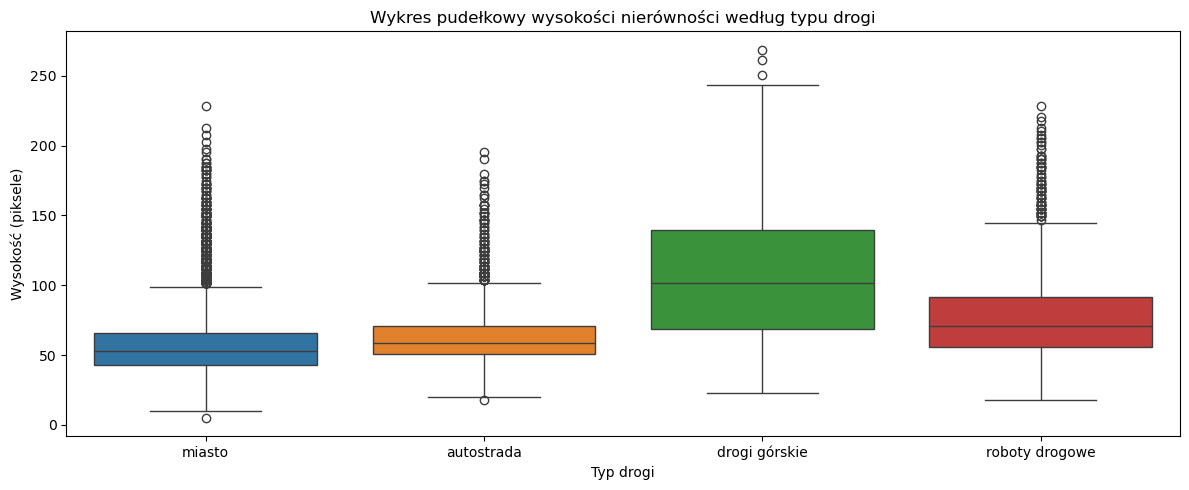

In [ ]:
plt.figure(figsize=(12, 5))
ax = sns.boxplot(data=df_meta, x="Typ drogi", y="h", hue="Typ drogi", showfliers=True)
ax.set_title("Wykres pudełkowy wysokości nierówności według typu drogi")
ax.set_xlabel("Typ drogi")
ax.set_ylabel("Wysokość (piksele)")
plt.tight_layout()
plt.savefig("../data/figures/box_wysokosc_typ_drogi.png", dpi=300, bbox_inches="tight")
plt.show()

- Autostrady: największa mediana szerokości (~400 px) i bardzo szeroki rozrzut (outliery sięgające 1200 px).
- Drogi miejskie: najmniejsza mediana (~120 px), mało bardzo dużych anomalii.
- Drogi górskie: mniejsze mediany szerokości (~150 px), ale za to największe mediany wysokości (~100 px) – dziury bardziej „głębokie”.
- Roadworks: umiarkowane wartości, szerokość i wysokość są średnie.

Wniosek: na autostradach dominują szerokie, płaskie uszkodzenia; w górach – węższe, ale głębsze; w miastach i na remontach – mniejsze uszkodzenia.

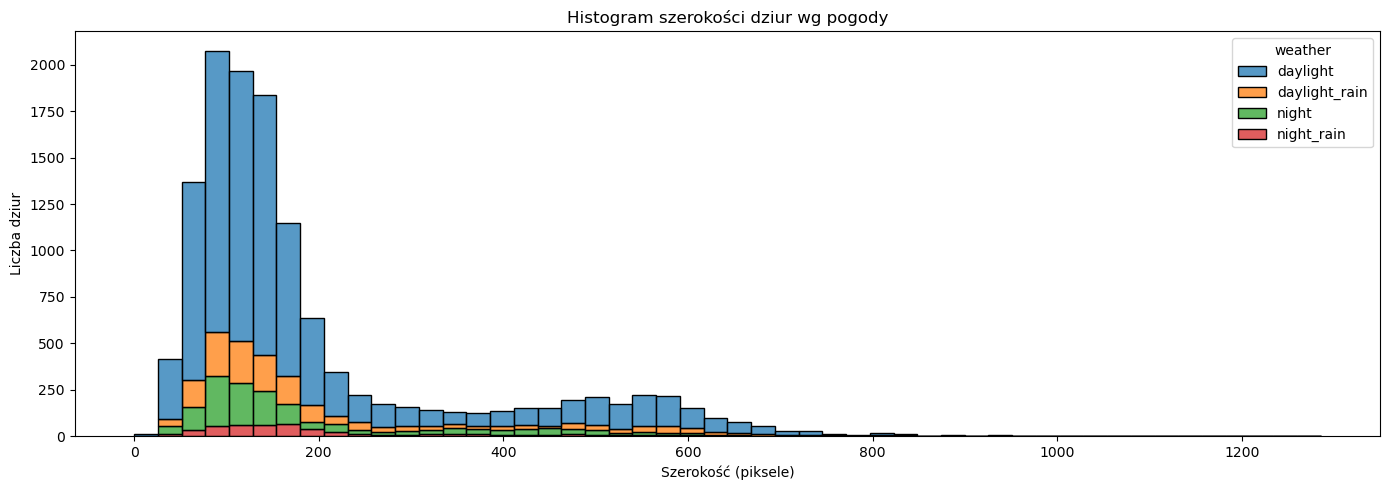

In [81]:
plt.figure(figsize=(14, 5))
sns.histplot(data=df_meta, x="w", hue="weather", multiple="stack", bins=50)
plt.title("Histogram szerokości dziur wg pogody")
plt.xlabel("Szerokość (piksele)")
plt.ylabel("Liczba dziur")
plt.tight_layout()
plt.show()

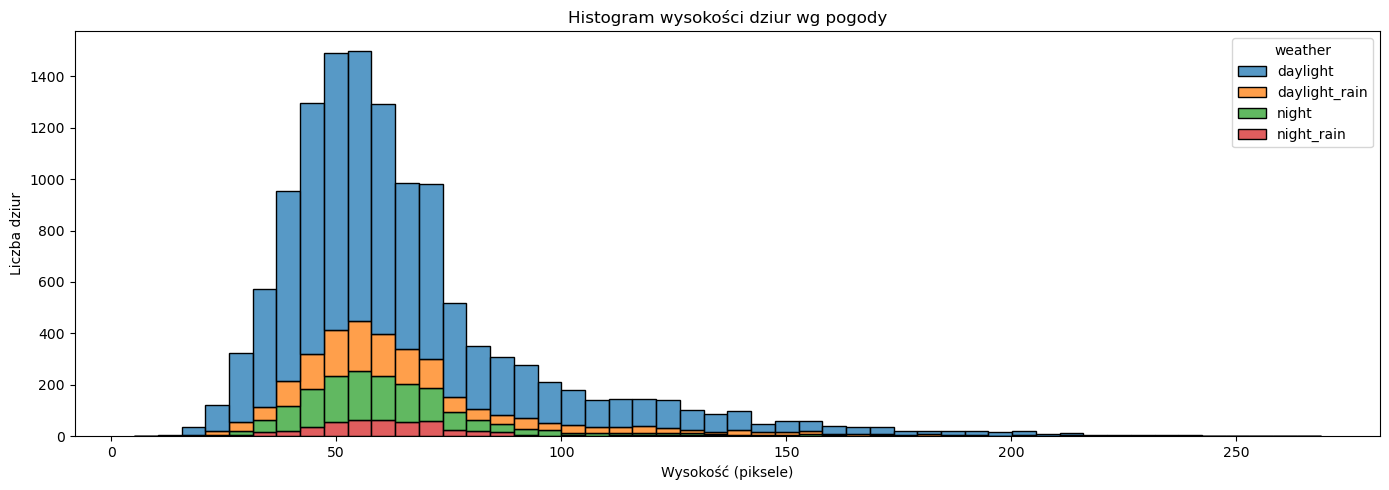

In [82]:
plt.figure(figsize=(14, 5))
sns.histplot(data=df_meta, x="h", hue="weather", multiple="stack", bins=50)
plt.title("Histogram wysokości dziur wg pogody")
plt.xlabel("Wysokość (piksele)")
plt.ylabel("Liczba dziur")
plt.tight_layout()
plt.show()

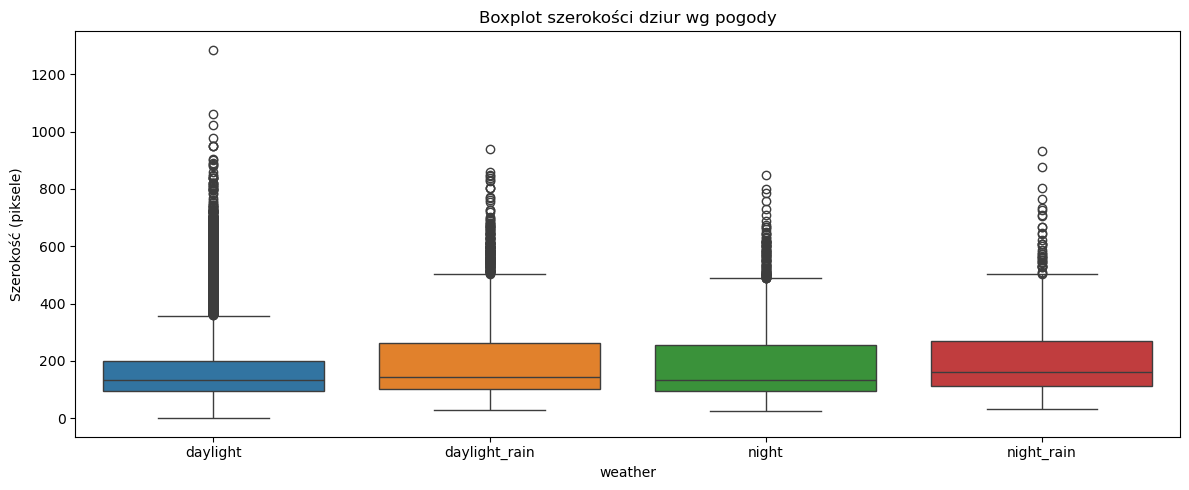

In [72]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_meta, x="weather", y="w", hue="weather", legend=False)
plt.title("Boxplot szerokości dziur wg pogody")
plt.ylabel("Szerokość (piksele)")
plt.tight_layout()
plt.show()

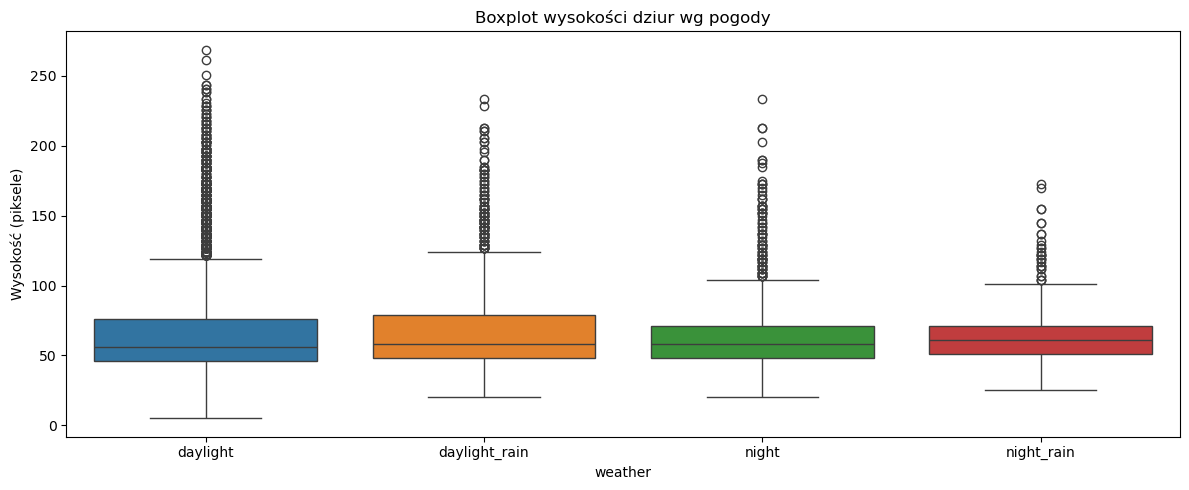

In [73]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_meta, x="weather", y="h", hue="weather", legend=False)
plt.title("Boxplot wysokości dziur wg pogody")
plt.ylabel("Wysokość (piksele)")
plt.tight_layout()
plt.show()

- Rozkłady dla pogody (daylight, rain, night) są podobne.
- Nie widać wyraźnego przesunięcia median ani większych outlierów w zależności od pogody.
- Widać, że najwięcej dziur jest w dzień (największy wolumen detekcji – ale to może wynikać z większej liczby nagrań).

Wniosek: pogoda ma mniejszy wpływ na wielkość detekcji, bardziej na ilość (bo w deszczu i nocy dane mogą być mniej liczne).

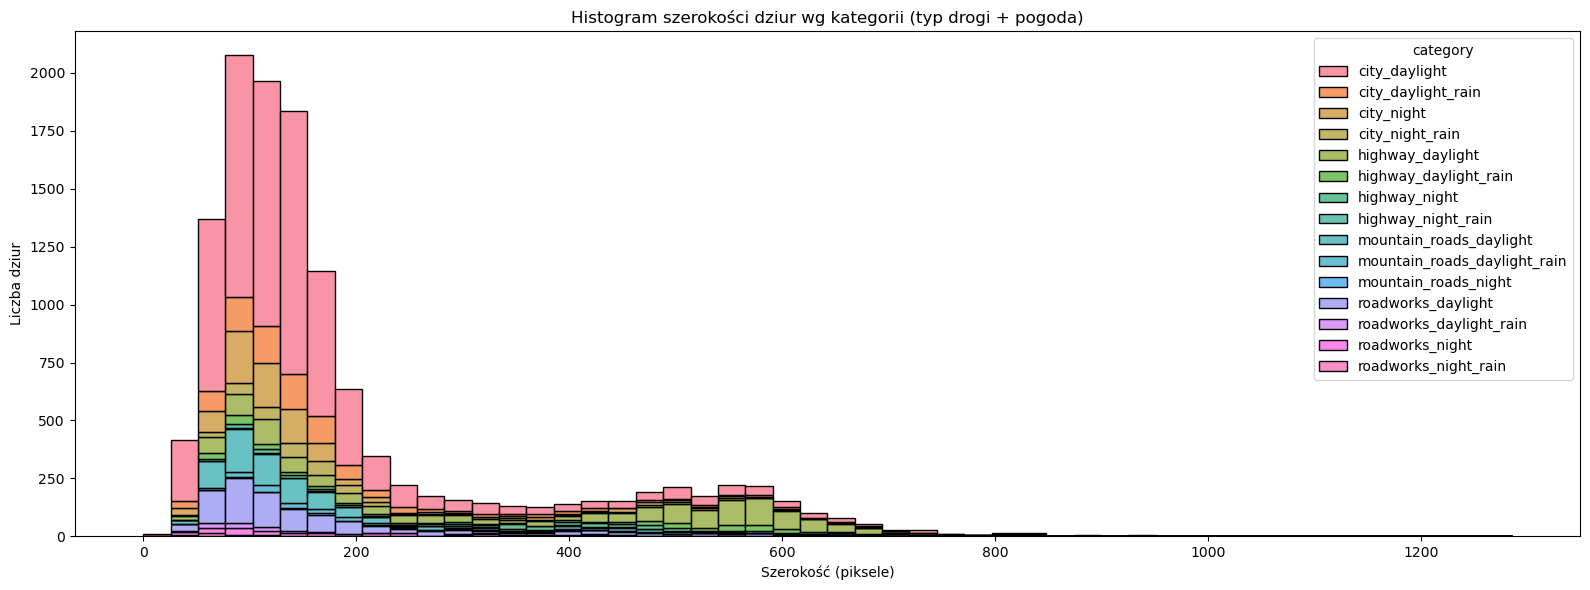

In [83]:
# Histogram szerokości wg pełnej kategorii (typ drogi + pogoda)
plt.figure(figsize=(16, 6))
sns.histplot(data=df_meta, x="w", hue="category", multiple="stack", bins=50)
plt.title("Histogram szerokości dziur wg kategorii (typ drogi + pogoda)")
plt.xlabel("Szerokość (piksele)")
plt.ylabel("Liczba dziur")
plt.tight_layout()
plt.show()

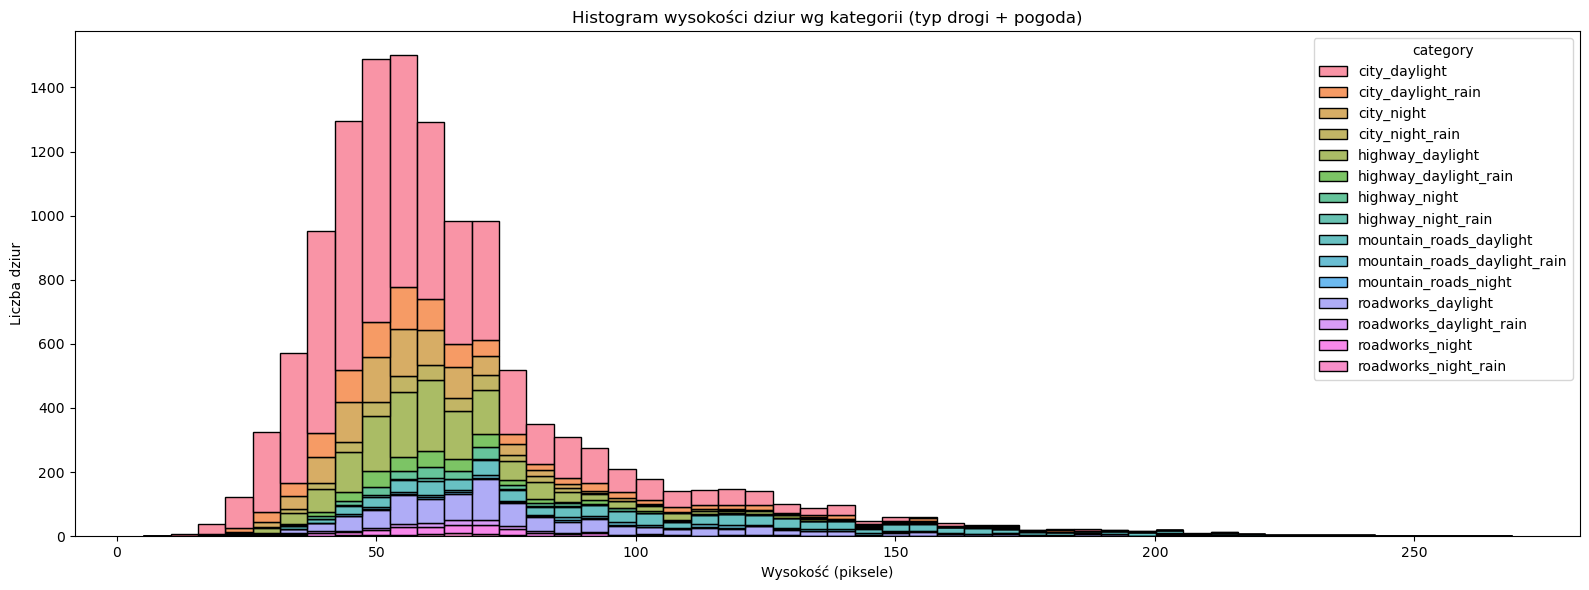

In [84]:
plt.figure(figsize=(16, 6))
sns.histplot(data=df_meta, x="h", hue="category", multiple="stack", bins=50)
plt.title("Histogram wysokości dziur wg kategorii (typ drogi + pogoda)")
plt.xlabel("Wysokość (piksele)")
plt.ylabel("Liczba dziur")
plt.tight_layout()
plt.show()

In [41]:
weather_map = {
    "daylight": "dzień",
    "daylight_rain": "dzień i deszcz",
    "night": "noc",
    "night_rain": "noc i deszcz",
}
dfw = df_meta.copy()
dfw["Pogoda"] = dfw["weather"].map(weather_map).fillna(df_meta["weather"])

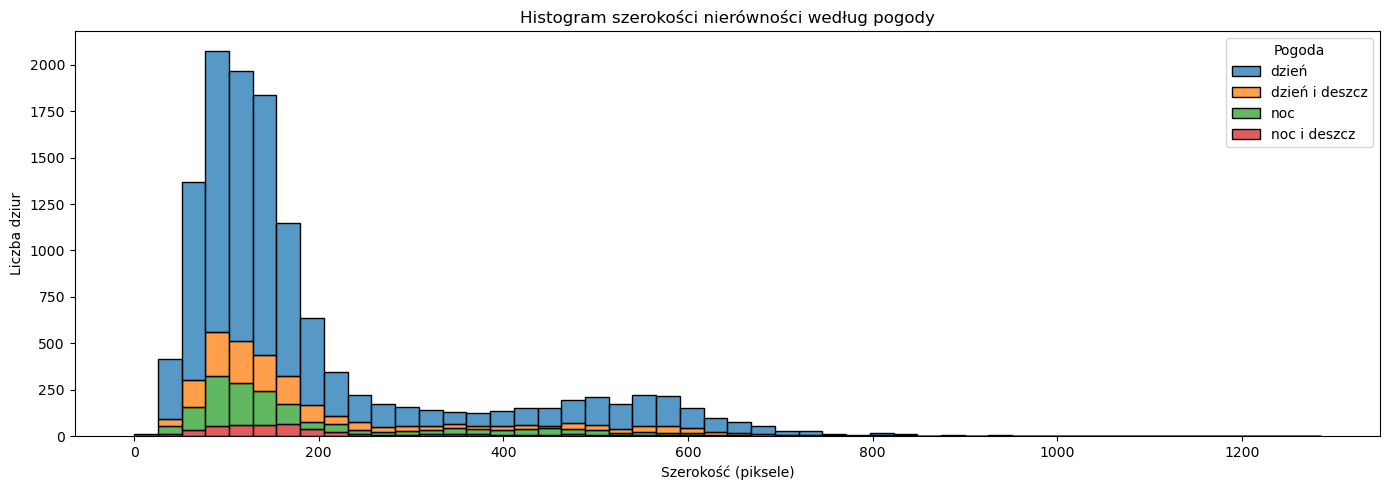

In [42]:
plt.figure(figsize=(14, 5))
sns.histplot(data=dfw, x="w", hue="Pogoda", multiple="stack", bins=50)
plt.title("Histogram szerokości nierówności według pogody")
plt.xlabel("Szerokość (piksele)")
plt.ylabel("Liczba dziur")
plt.tight_layout()
plt.savefig("../data/figures/hist_szerokosc_pogoda.png", dpi=300, bbox_inches="tight")
plt.show()

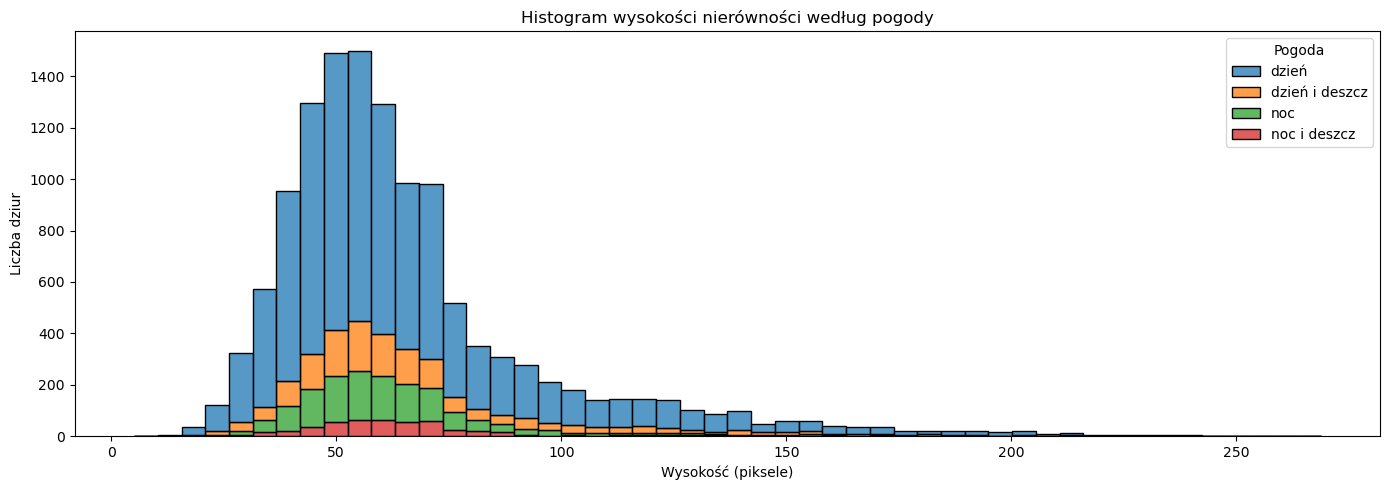

In [43]:
plt.figure(figsize=(14, 5))
sns.histplot(data=dfw, x="h", hue="Pogoda", multiple="stack", bins=50)
plt.title("Histogram wysokości nierówności według pogody")
plt.xlabel("Wysokość (piksele)")
plt.ylabel("Liczba dziur")
plt.tight_layout()
plt.savefig("../data/figures/hist_wysokosc_pogoda.png", dpi=300, bbox_inches="tight")
plt.show()

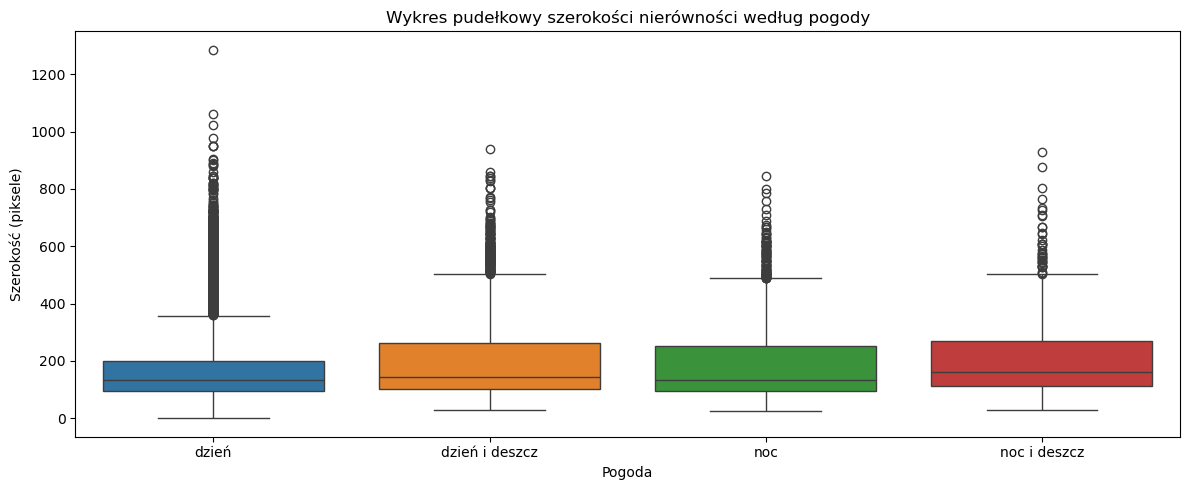

In [49]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=dfw, x="Pogoda", y="w", hue="Pogoda", legend=False)
plt.title("Wykres pudełkowy szerokości nierówności według pogody")
plt.ylabel("Szerokość (piksele)")
plt.tight_layout()
plt.savefig("../data/figures/box_szerokosc_pogoda.png", dpi=300, bbox_inches="tight")
plt.show()

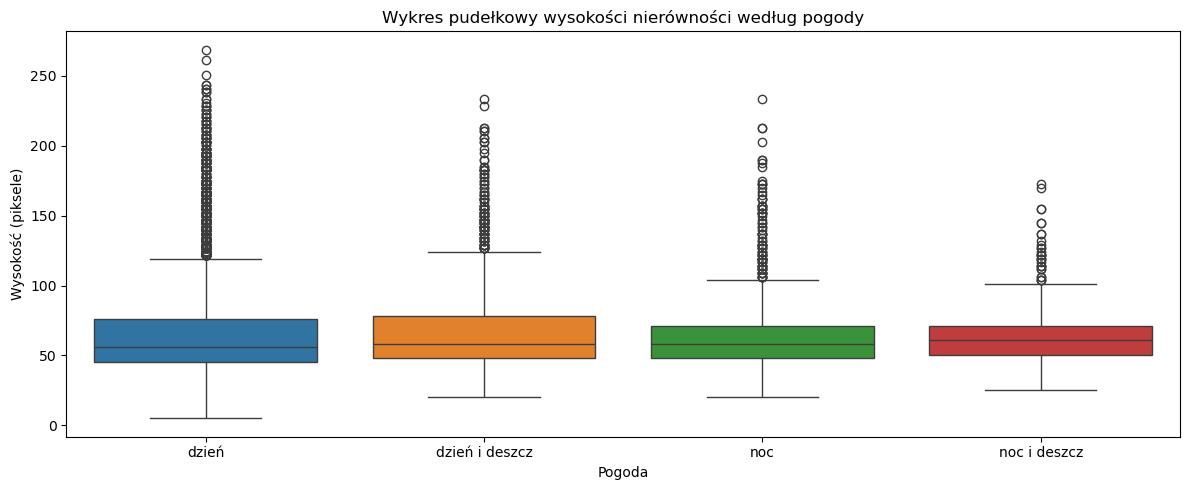

In [48]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=dfw, x="Pogoda", y="h", hue="Pogoda", legend=False)
plt.title("Wykres pudełkowy wysokości nierówności według pogody")
plt.xlabel("Pogoda")
plt.ylabel("Wysokość (piksele)")
plt.tight_layout()
plt.savefig("../data/figures/box_wysokosc_pogoda.png", dpi=300, bbox_inches="tight")
plt.show()

- Najwięcej detekcji pochodzi z kategorii miejskich (city_daylight).
- Największe szerokości dziur są w kategoriach autostradowych, niezależnie od pogody.
- Nie ma wyraźnych przesunięć w rozkładach szerokości/wysokości zależnych od pogody – dominującym czynnikiem jest typ drogi.

Podsumowanie:
- Typ drogi ma zdecydowanie większy wpływ na szerokość i wysokość dziur niż pogoda.
- Autostrady – szerokie, płaskie uszkodzenia.
- Góry – bardziej „wysokie” (duże h), węższe w szerokości.
- Miasta – wiele małych uszkodzeń.
- Pogoda – nie zmienia znacząco rozkładu rozmiarów, tylko liczbę detekcji.

## Analiza aspect ratio (w/h)

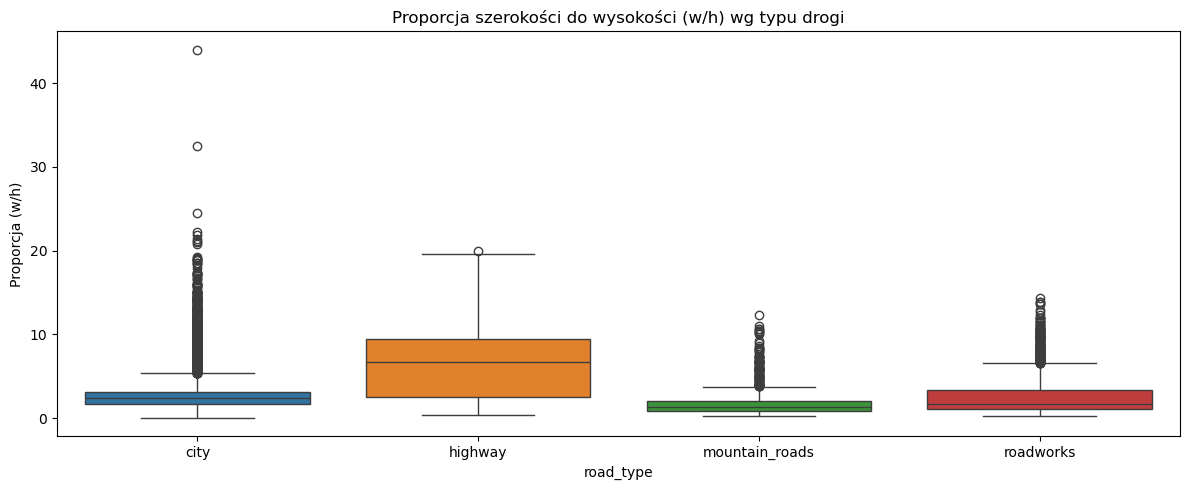

In [ ]:
# Dla road_type
plt.figure(figsize=(12, 5))
sns.boxplot(
    data=df_meta, x="road_type", y="aspect_ratio", hue="road_type", legend=False
)
plt.title("Proporcja szerokości do wysokości (w/h) wg typu drogi")
plt.ylabel("Proporcja (w/h)")
plt.tight_layout()
plt.show()

Typ drogi ma największy wpływ na rozmiary dziur (p < 0.00001 dla wszystkich metryk)

- Autostrady (highway) – najwyższa proporcja w/h (mediana ~7–8), co oznacza, że dziury są wyraźnie szersze niż wyższe - mogą to być długie koleiny lub pęknięcia wzdłużne.
- Drogi miejskie (city) – najwięcej anomalii, ale proporcja w/h bliżej 2–3, czyli dziury bardziej „regularne” (mniej wydłużone).
- Drogi górskie (mountain_roads) – najniższa proporcja w/h (~1–2), co sugeruje bardziej pionowe (głębokie) uszkodzenia niż szerokie.
- Drogi w remontach (roadworks) – rozkład zbliżony do miejskich, ale z większym odchyleniem (wiele małych, ale też kilka wydłużonych anomalii).

Znaczenie praktyczne: \
Różne profile uszkodzeń mogą wymagać innych algorytmów predykcji i reakcji zawieszenia:
- Autostrady – system musi rozpoznawać i łagodzić wydłużone koleiny (np. poprzez regulację toru jazdy).
- Góry – bardziej pionowe uderzenia (konieczna amortyzacja).

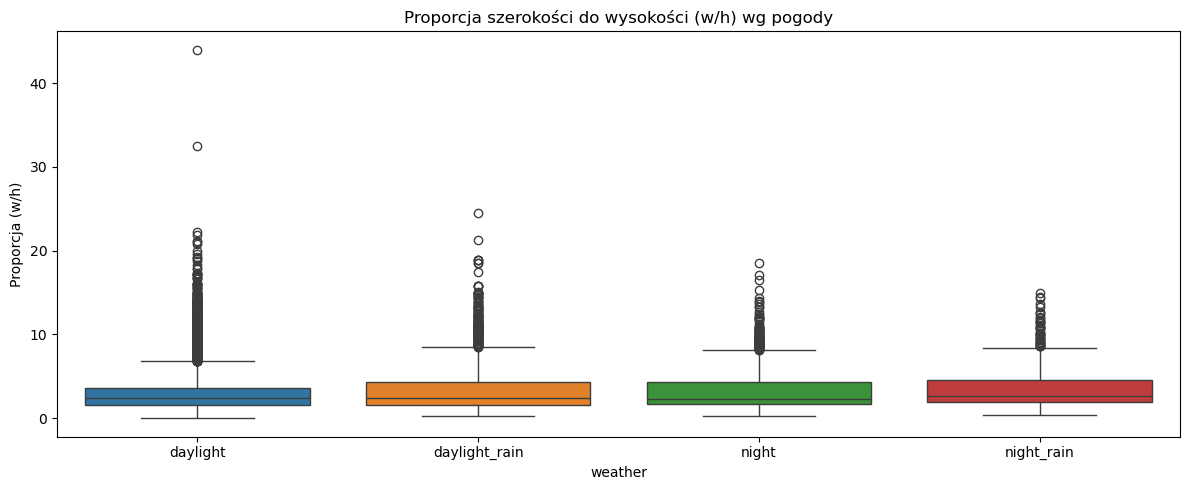

In [76]:
# Dla weather
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_meta, x="weather", y="aspect_ratio", hue="weather", legend=False)
plt.title("Proporcja szerokości do wysokości (w/h) wg pogody")
plt.ylabel("Proporcja (w/h)")
plt.tight_layout()
plt.show()

Testy Kruskala dla pogody też dały p < 0.0001 (różnice istotne statystycznie), ale:
- Mediany szerokości, wysokości i w/h są dość podobne między kategoriami pogodowymi.
- Różnice wynikają głównie z mniejszej liczby obserwacji w deszczu i nocy (mogą pojawiać się pojedyncze duże outliery, co wpływa na wynik statystyczny). 

Wniosek: wpływ pogody jest widoczny, ale raczej nie zmienia charakterystyki dziur, a jedynie może zwiększać rozrzut (szum w danych z deszczu i nocnych nagrań).

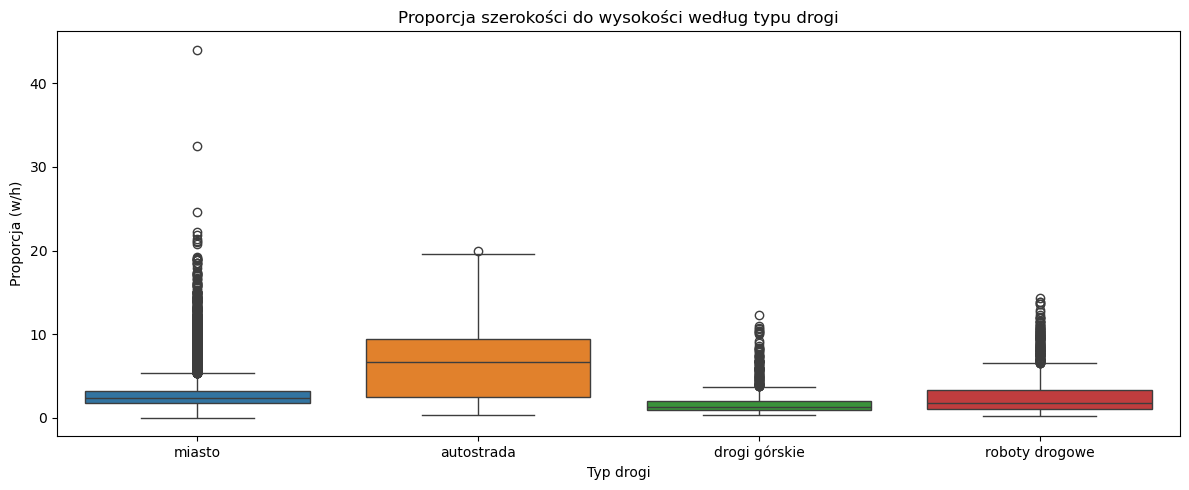

In [52]:
plt.figure(figsize=(12, 5))
sns.boxplot(
    data=df_meta, x="Typ drogi", y="aspect_ratio", hue="Typ drogi", legend=False
)
plt.title("Proporcja szerokości do wysokości według typu drogi")
plt.xlabel("Typ drogi")
plt.ylabel("Proporcja (w/h)")
plt.tight_layout()
plt.savefig("../data/figures/box_wh_typ_drogi_PL.png", dpi=300, bbox_inches="tight")
plt.show()

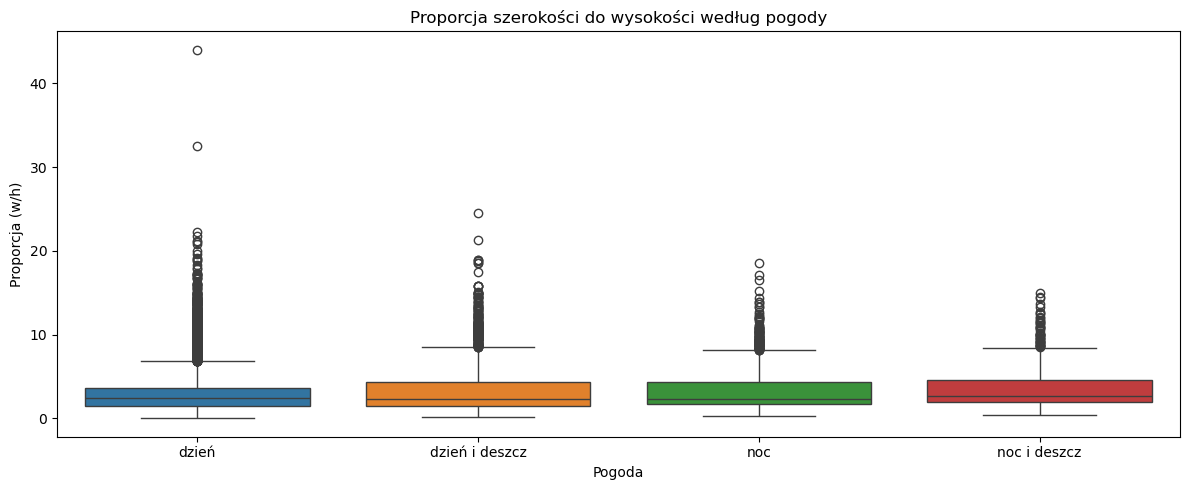

In [ ]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=dfw, x="Pogoda", y="aspect_ratio", hue="Pogoda", legend=False)
plt.title("Proporcja szerokości do wysokości według pogody")
plt.xlabel("Pogoda")
plt.ylabel("Proporcja (w/h)")
plt.tight_layout()
plt.savefig("../data/figures/box_wh_pogoda_PL.png", dpi=300, bbox_inches="tight")
plt.show()

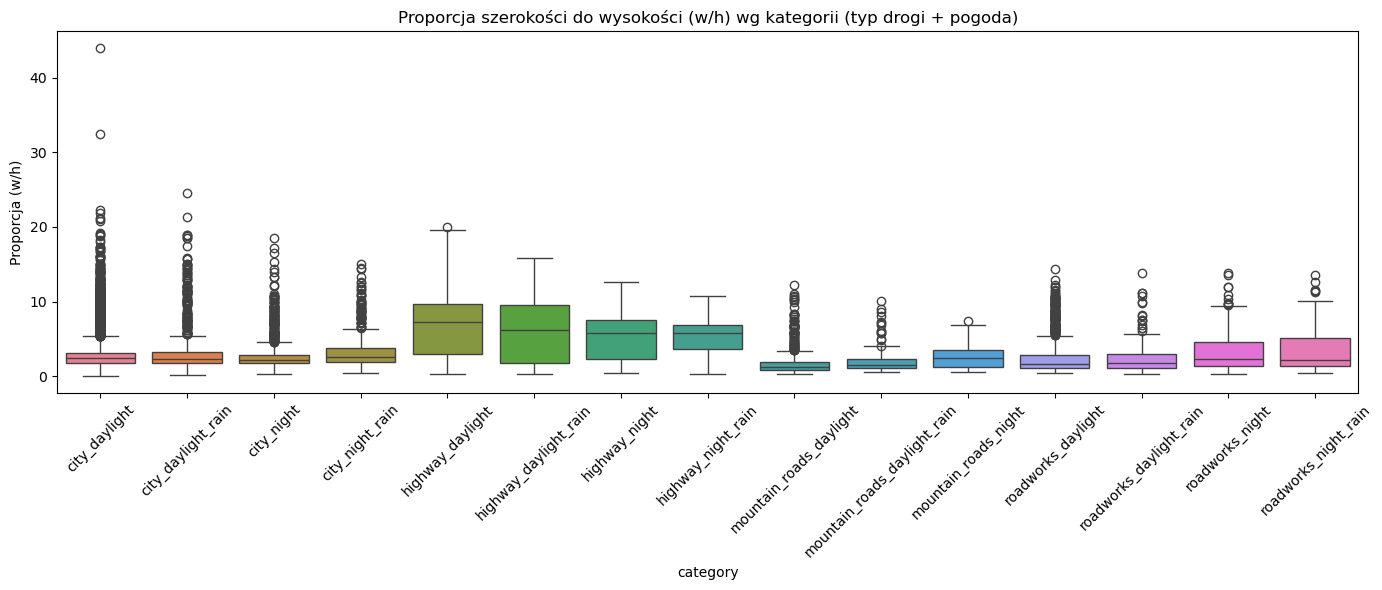

In [51]:
# Boxplot wg category (pełne połączenie)
plt.figure(figsize=(14, 6))
sns.boxplot(data=df_meta, x="category", y="aspect_ratio", hue="category", legend=False)
plt.title("Proporcja szerokości do wysokości (w/h) wg kategorii (typ drogi + pogoda)")
plt.ylabel("Proporcja (w/h)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Pełne kategorie (typ drogi + pogoda) pokazują, że dominującym czynnikiem jest jednak typ drogi
- W boxplotach dla category widać, że największe różnice wynikają z samego rodzaju drogi, a nie pogody.
- W deszczu i w nocy pojawia się więcej odchyleń (outlierów), co sugeruje, że warunki wpływają bardziej na jakość detekcji niż realną wielkość dziur.

## Korelacja rozmiaru dziury z warunkami nagrania

In [ ]:
# Pogoda
groups_w_weather = [
    df_meta.loc[df_meta["weather"] == w, "w"] for w in df_meta["weather"].unique()
]
stat_w_weather, p_w_weather = kruskal(*groups_w_weather)

groups_h_weather = [
    df_meta.loc[df_meta["weather"] == w, "h"] for w in df_meta["weather"].unique()
]
stat_h_weather, p_h_weather = kruskal(*groups_h_weather)

groups_ar_weather = [
    df_meta.loc[df_meta["weather"] == w, "aspect_ratio"]
    for w in df_meta["weather"].unique()
]
stat_ar_weather, p_ar_weather = kruskal(*groups_ar_weather)

print(
    f"[POGODA] Kruskal-Wallis dla szerokości: stat={stat_w_weather:.3f}, p={p_w_weather:.5f}"
)
print(
    f"[POGODA] Kruskal-Wallis dla wysokości: stat={stat_h_weather:.3f}, p={p_h_weather:.5f}"
)
print(
    f"[POGODA] Kruskal-Wallis dla aspect_ratio: stat={stat_ar_weather:.3f}, p={p_ar_weather:.5f}"
)

[POGODA] Kruskal-Wallis dla szerokości: stat=69.191, p=0.00000
[POGODA] Kruskal-Wallis dla wysokości: stat=36.368, p=0.00000
[POGODA] Kruskal-Wallis dla aspect_ratio: stat=22.367, p=0.00005


In [ ]:
# Typ drogi
groups_w_road = [
    df_meta.loc[df_meta["road_type"] == r, "w"] for r in df_meta["road_type"].unique()
]
stat_w_road, p_w_road = kruskal(*groups_w_road)

groups_h_road = [
    df_meta.loc[df_meta["road_type"] == r, "h"] for r in df_meta["road_type"].unique()
]
stat_h_road, p_h_road = kruskal(*groups_h_road)

groups_ar_road = [
    df_meta.loc[df_meta["road_type"] == r, "aspect_ratio"]
    for r in df_meta["road_type"].unique()
]
stat_ar_road, p_ar_road = kruskal(*groups_ar_road)

print(
    f"[TYP DROGI] Kruskal-Wallis dla szerokości: stat={stat_w_road:.3f}, p={p_w_road:.5f}"
)
print(
    f"[TYP DROGI] Kruskal-Wallis dla wysokości: stat={stat_h_road:.3f}, p={p_h_road:.5f}"
)
print(
    f"[TYP DROGI] Kruskal-Wallis dla aspect_ratio: stat={stat_ar_road:.3f}, p={p_ar_road:.5f}"
)

[TYP DROGI] Kruskal-Wallis dla szerokości: stat=1508.396, p=0.00000
[TYP DROGI] Kruskal-Wallis dla wysokości: stat=1852.351, p=0.00000
[TYP DROGI] Kruskal-Wallis dla aspect_ratio: stat=1909.118, p=0.00000


In [ ]:
# Dla pełnej kategorii (typ drogi + pogoda)
groups_w_cat = [
    df_meta.loc[df_meta["category"] == c, "w"] for c in df_meta["category"].unique()
]
stat_w_cat, p_w_cat = kruskal(*groups_w_cat)

groups_h_cat = [
    df_meta.loc[df_meta["category"] == c, "h"] for c in df_meta["category"].unique()
]
stat_h_cat, p_h_cat = kruskal(*groups_h_cat)

groups_ar_cat = [
    df_meta.loc[df_meta["category"] == c, "aspect_ratio"]
    for c in df_meta["category"].unique()
]
stat_ar_cat, p_ar_cat = kruskal(*groups_ar_cat)

print(
    f"[KATEGORIA (typ drogi + pogoda)] Szerokość: stat={stat_w_cat:.3f}, p={p_w_cat:.5f}"
)
print(f"[KATEGORIA] Wysokość: stat={stat_h_cat:.3f}, p={p_h_cat:.5f}")
print(f"[KATEGORIA] Aspect ratio: stat={stat_ar_cat:.3f}, p={p_ar_cat:.5f}")

[KATEGORIA (typ drogi + pogoda)] Szerokość: stat=1699.786, p=0.00000
[KATEGORIA] Wysokość: stat=1979.903, p=0.00000
[KATEGORIA] Aspect ratio: stat=2020.568, p=0.00000


* Wszystkie p-value ≪ 0.05 – różnice są statystycznie istotne.
* Najsilniejszy efekt (największe statystyki) widać dla:
    - Typu drogi (road_type) – największe różnice w szerokości, wysokości i w/h.
    - Pełnej kategorii (road_type + weather) – połączenie wpływów, ale główny czynnik to wciąż droga.
    - Pogoda – wpływ statystyczny, ale słabszy.